# Lets build Mamba2 from scratch

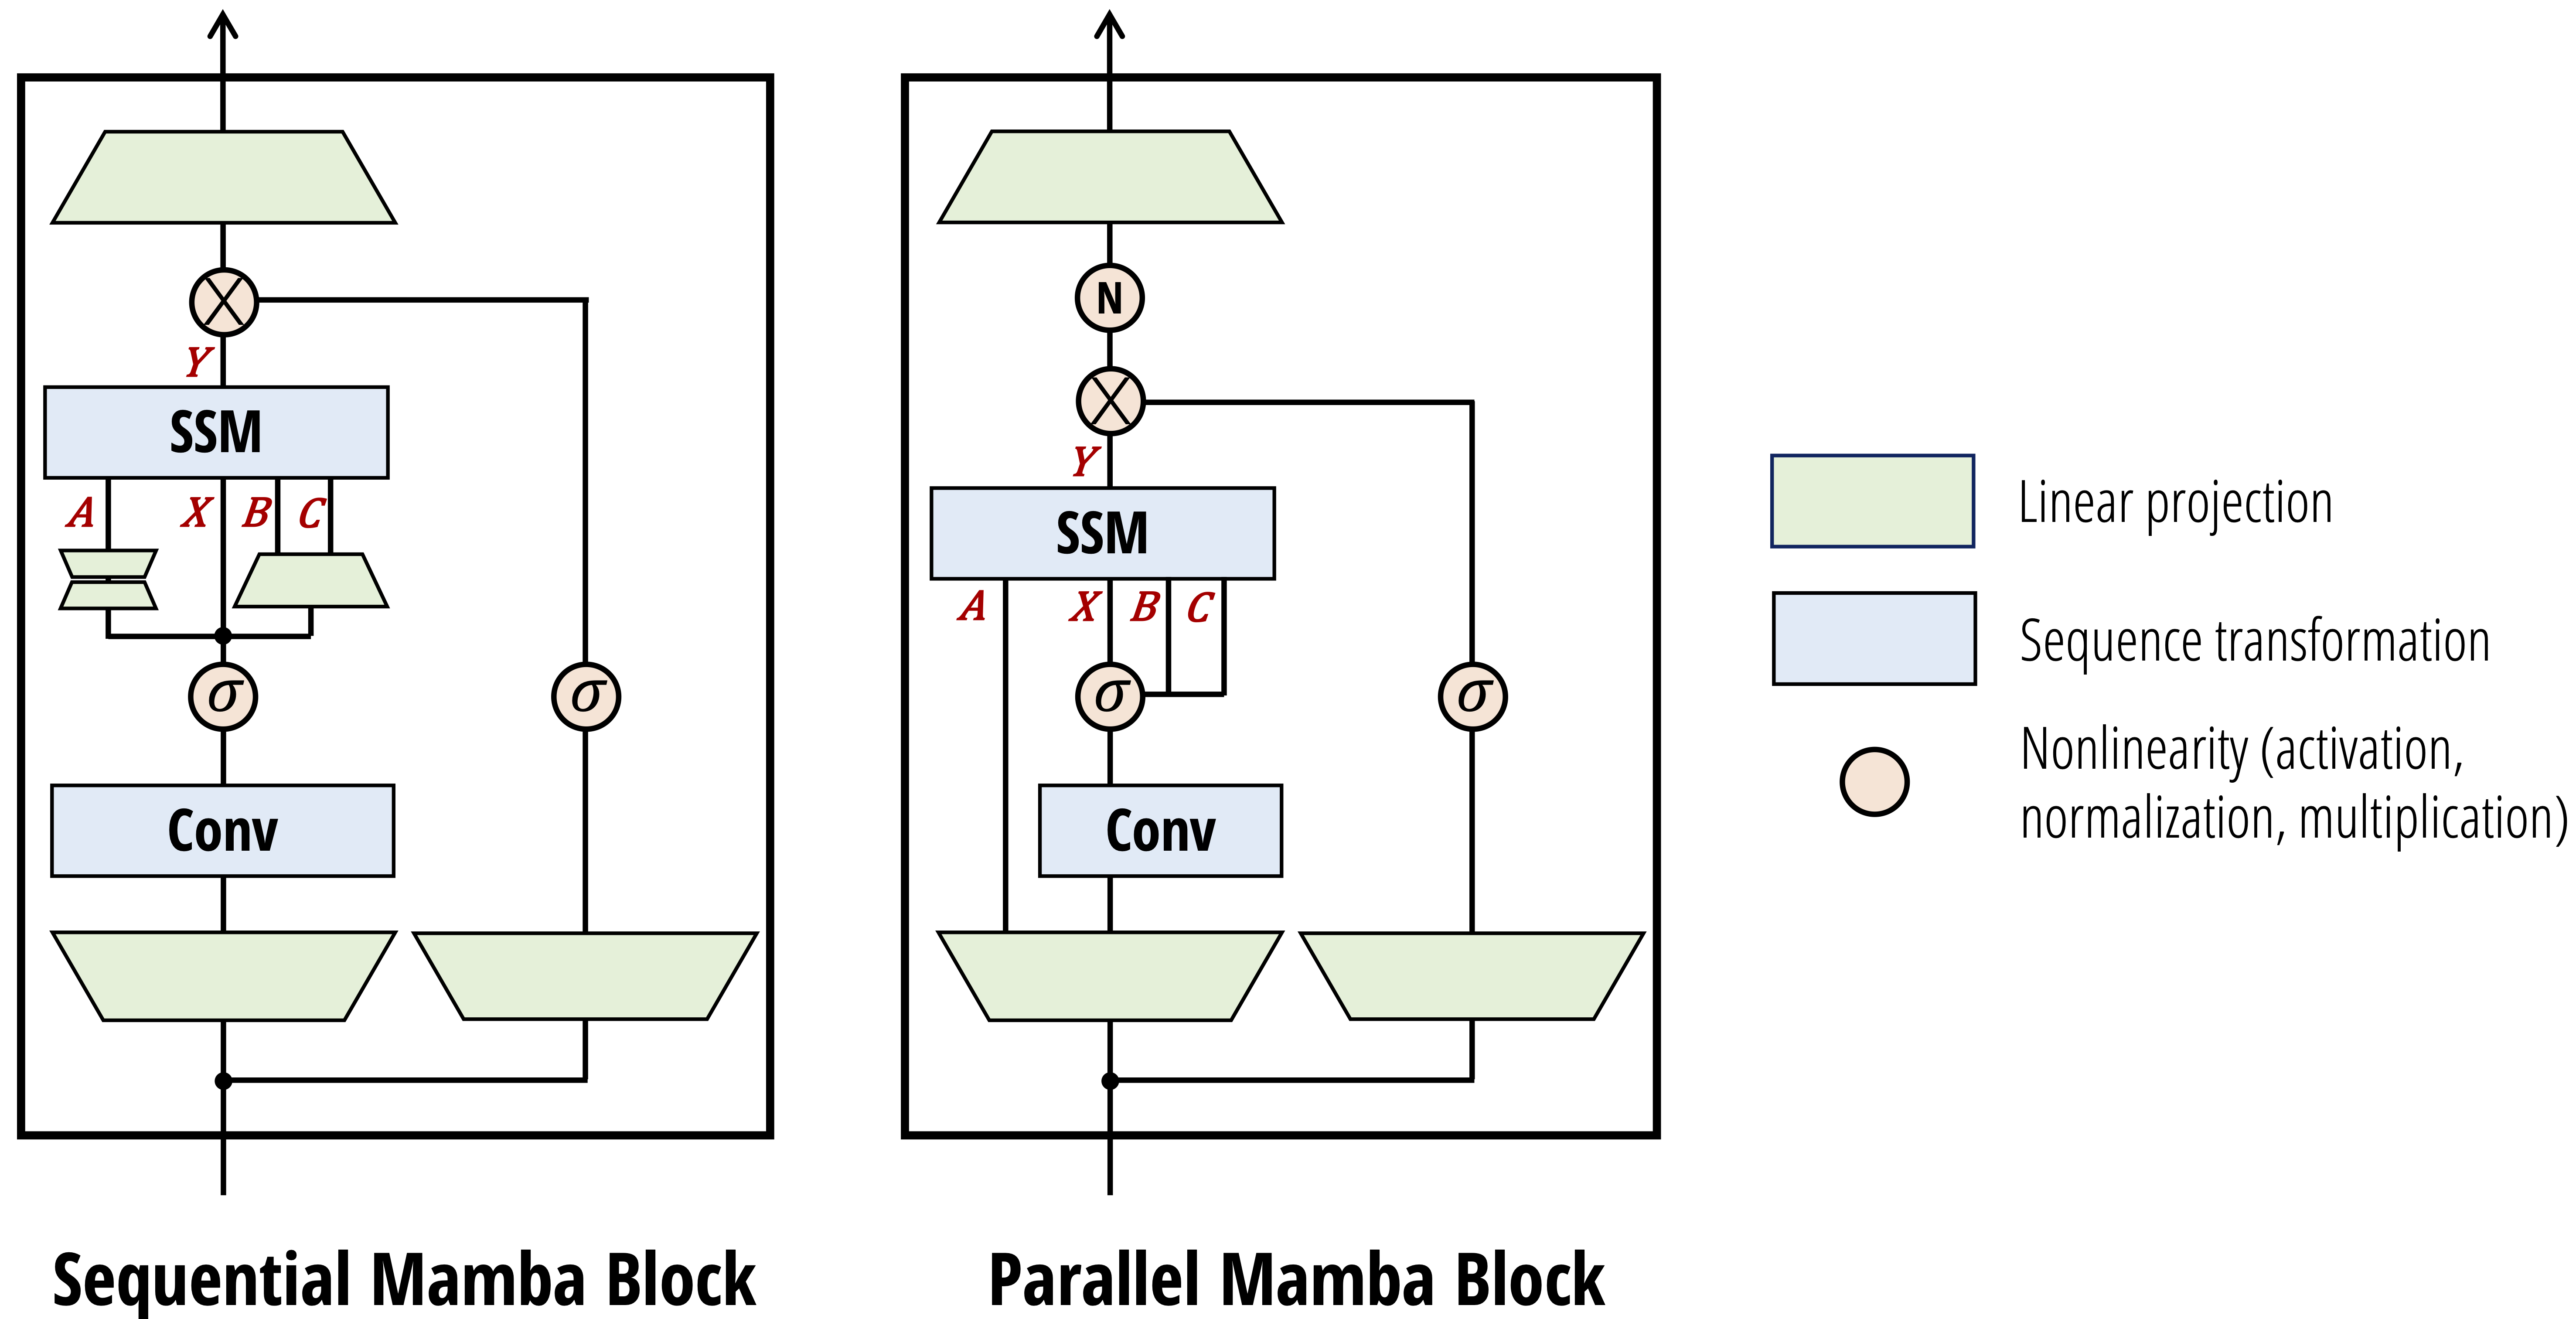

In [1]:
import math
from typing import Optional, Union, Tuple
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers.activations import ACT2FN

/Users/saul/Projects/projects/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Configuration

In [2]:
@dataclass
class Mamba2Config:
    """
    Configuration for a Mamba2 model.

    This is a lightweight, PyTorch-native configuration container with no
    dependency on Hugging Face's `PretrainedConfig`. You can pass it directly
    into your `torch.nn.Module` implementation.

    Args:
        num_heads: Number of heads for the evolution matrices of Mamba 2.
        head_dim: Dimension of each head.
        vocab_size: Vocabulary size (number of distinct token IDs).
        hidden_size: Dimensionality of embeddings and hidden states.
        state_size: Shape of the state space latents.
        num_hidden_layers: Number of mixer blocks / layers.
        layer_norm_epsilon: Epsilon used in layer normalization / RMS norm.
        pad_token_id: Padding token id.
        bos_token_id: Beginning-of-sentence token id.
        eos_token_id: End-of-sentence token id.
        expand: Expanding factor used to determine intermediate size.
        conv_kernel: Size of the convolution kernel.
        n_groups: Number of groups for the evolution matrices.
        use_bias: Whether to use bias in ["in_proj", "out_proj"] of the mixer.
        use_conv_bias: Whether to use bias in the convolution layer.
        hidden_act: Non-linear activation function name (e.g. "silu").
        initializer_range: Std of truncated normal initializer for weights.
        residual_in_fp32: Whether residuals should be in float32.
        time_step_rank: Rank of discretization projection matrix, or "auto"
            to use ceil(hidden_size / 16).
        time_step_min: Minimum time step used to bound dt_proj.bias.
        time_step_max: Maximum time step used to bound dt_proj.bias.
        time_step_floor: Minimum clamping value for dt_proj.bias init.
        time_step_limit: Accepted range of time step values.
        rescale_prenorm_residual: Whether to rescale out_proj weights at init.
        use_cache: Whether to use a cache for incremental decoding.
        rms_norm: Whether to use RMSNorm (otherwise LayerNorm).
        chunk_size: Size of chunks used to process long sequences.
        tie_word_embeddings: Whether to tie input and output embeddings.
    """

    num_heads: int = 128
    head_dim: int = 64
    vocab_size: int = 32_768
    hidden_size: int = 4_096
    state_size: int = 128
    num_hidden_layers: int = 64
    layer_norm_epsilon: float = 1e-5

    pad_token_id: int = 1
    bos_token_id: int = 0
    eos_token_id: int = 2

    expand: int = 2
    conv_kernel: int = 4
    n_groups: int = 8

    use_bias: bool = False
    use_conv_bias: bool = True
    hidden_act: str = "silu"
    initializer_range: float = 0.1
    residual_in_fp32: bool = True

    time_step_rank: Union[int, str] = "auto"
    time_step_min: float = 0.001
    time_step_max: float = 0.1
    time_step_floor: float = 1e-4
    time_step_limit: Tuple[float, float] = (0.0, float("inf"))

    rescale_prenorm_residual: bool = False
    use_cache: bool = True
    rms_norm: bool = True
    chunk_size: int = 256
    tie_word_embeddings: bool = False

    def __post_init__(self) -> None:
        # Resolve "auto" → concrete rank
        if self.time_step_rank == "auto":
            self.time_step_rank = math.ceil(self.hidden_size / 16)

        # Sanity check on expansion vs heads * head_dim
        if (self.hidden_size * self.expand) != (self.num_heads * self.head_dim):
            raise ValueError(
                "Inconsistent configuration: hidden_size * expand "
                f"({self.hidden_size * self.expand}) must equal "
                f"num_heads * head_dim ({self.num_heads * self.head_dim})."
            )

# Helper Functions

In [3]:
def pad_tensor_by_size(input_tensor: torch.Tensor, pad_size: int):
    """
    Padding x tensor with `pad_size` on the seq_len dim (dim=1)

    Assumes that we only have tensors of either size 4 or 3

    WHY WE NEED THIS:
    ----------------
    Mamba2 processes sequences in fixed-size chunks (e.g., chunk_size=64).
    If your sequence length isn't evenly divisible by chunk_size, we need padding.

    Example:
        seq_len = 100, chunk_size = 64
        100 % 64 = 36 (remainder)
        pad_size = 64 - 36 = 28
        After padding: 100 + 28 = 128 = 2 * 64 (exactly 2 chunks)

    This allows us to reshape the sequence into uniform chunks for parallel processing.
    """

    # PyTorch's F.pad takes a tuple that specifies padding for each dimension
    # The tuple is read FROM RIGHT TO LEFT (last dimension to first dimension)
    # Format: (last_dim_left, last_dim_right, 2nd_last_left, 2nd_last_right, ...)

    # For 4D tensor with shape: [batch_size, seq_len, num_heads, head_dim]
    # Dimensions are indexed as: [0, 1, 2, 3]
    # pad_shape tuple order:     [3, 3, 2, 2, 1, 1, 0, 0]
    #                            [head_dim, num_heads, seq_len, batch]
    if len(input_tensor.shape) == 4:
        pad_shape = (
            0,
            0,  # head_dim (dim=3): no padding on left or right
            0,
            0,  # num_heads (dim=2): no padding on left or right
            0,
            pad_size,  # seq_len (dim=1): 0 padding on left, pad_size on right
            0,
            0,  # batch_size (dim=0): no padding on left or right
        )

    # For 3D tensor with shape: [batch_size, seq_len, hidden_dim]
    # Dimensions are indexed as: [0, 1, 2]
    # pad_shape tuple order:     [2, 2, 1, 1, 0, 0]
    #                            [hidden_dim, seq_len, batch]
    else:
        pad_shape = (
            0,
            0,  # hidden_dim (dim=2): no padding on left or right
            0,
            pad_size,  # seq_len (dim=1): 0 padding on left, pad_size on right
            0,
            0,  # batch_size (dim=0): no padding on left or right
        )

    # Apply padding with zeros (constant mode, value=0)
    # This extends the sequence length by pad_size, filling new positions with 0
    # Shape change examples:
    #   3D: [batch, 100, hidden] -> [batch, 128, hidden]
    #   4D: [batch, 100, heads, dim] -> [batch, 128, heads, dim]
    return F.pad(input_tensor, pad_shape, mode="constant", value=0)


# Example usage:
# (batch_size, seq_len, num_heads, head_dim)
x = torch.randn(2, 100, 4, 16)  # Example 4D tensor
pad_size = 28  # Example pad size
padded_x = pad_tensor_by_size(x, pad_size)
print(padded_x.shape)  # Should print torch.Size([2, 128, 4, 16])

torch.Size([2, 128, 4, 16])


In [4]:
def reshape_into_chunks(input_tensor, pad_size, chunk_size):
    """
    Padding input_tensor with `pad_size` on the seq_len dim (dim=1) and
    simultaneously splitting it into chunk sequences.

    Assumes that we only have tensors of either size 4 or 3

    WHY WE NEED THIS:
    ----------------
    Mamba2 processes sequences in parallel chunks for efficiency.
    We need to RESHAPE (not split/slice) the sequence dimension by factoring it
    into two dimensions: (num_chunks, chunk_size)

    This allows parallel computation within chunks while maintaining sequential
    state updates between chunks.

    CONNECTION TO ATTENTION:
    ------------------------
    This is EXACTLY analogous to the head-splitting reshape in attention!

    In Attention, we FACTOR the feature dimension:
        [batch, seq_len, embed_dim]
        -> [batch, seq_len, num_heads, head_dim]
        where embed_dim = num_heads × head_dim

    In Mamba2, we FACTOR the sequence dimension:
        [batch, seq_len, num_heads]
        -> [batch, num_chunks, chunk_size, num_heads]
        where seq_len = num_chunks × chunk_size

    Both operations:
    - Are reshapes (no data movement, just changing the view)
    - Factor one dimension into two dimensions whose product equals the original
    - Enable parallelization (across heads / across chunks)

    Example factorization:
        embed_dim: 512 = 8 × 64    (8 heads, 64 dim per head)
        seq_len:   128 = 2 × 64    (2 chunks, 64 tokens per chunk)
    """

    # Step 1: Pad so seq_len is evenly divisible by chunk_size
    # Just like embed_dim must be divisible by num_heads in attention
    # [bsz, seq_len, ...] -> [bsz, seq_len multiple of chunk_size, ...]
    input_tensor = pad_tensor_by_size(input_tensor, pad_size)

    if len(input_tensor.shape) == 3:
        # [bsz, seq_len multiple of chunk_size, num_heads] -> [bsz, -1, chunk_size, num_heads]
        return input_tensor.reshape(
            input_tensor.shape[0],  # bsz: stays in dimension 0
            -1,  # num_chunks: inferred (seq_len ÷ chunk_size)
            chunk_size,  # chunk_size: explicit
            input_tensor.shape[2],  # num_heads: moves from dim 2 -> dim 3
        )

    else:
        # [bsz, seq_len multiple of chunk_size, num_heads, head_dim or state_size]
        # -> [bsz, -1, chunk_size, num_heads, head_dim or state_size]
        return input_tensor.reshape(
            input_tensor.shape[0],  # bsz: stays in dimension 0
            -1,  # num_chunks: inferred (seq_len ÷ chunk_size)
            chunk_size,  # chunk_size: explicit
            input_tensor.shape[2],  # num_heads: moves from dim 2 -> dim 3
            input_tensor.shape[3],  # head_dim: moves from dim 3 -> dim 4
        )


# DETAILED COMPARISON TO ATTENTION'S VIEW OPERATION:
# ===================================================

# ATTENTION - Factoring embed_dim into (num_heads, head_dim):
# ------------------------------------------------------------
# x = torch.randn(2, 128, 512)  # [bsz, seq_len, embed_dim]
# x = x.view(2, 128, 8, 64)     # [bsz, seq_len, num_heads, head_dim]
#
# What happened? 512 = 8 × 64
# Dimension 2 (size 512) was FACTORED into two dimensions (8, 64)
# No data was moved or copied - just a different way to view the same memory

# MAMBA2 - Factoring seq_len into (num_chunks, chunk_size):
# -----------------------------------------------------------
# x = torch.randn(2, 128, 8)    # [bsz, seq_len, num_heads]
# x = x.reshape(2, 2, 64, 8)    # [bsz, num_chunks, chunk_size, num_heads]
#
# What happened? 128 = 2 × 64
# Dimension 1 (size 128) was FACTORED into two dimensions (2, 64)
# No data was moved or copied - just a different way to view the same memory


# VISUAL - How the data is organized:
# ====================================
#
# Original 3D tensor: [bsz=1, seq_len=128, num_heads=8]
# Think of it as a grid where each cell is a vector of size 8:
#
# [tok0] [tok1] [tok2] ... [tok127]
#   ↓      ↓      ↓           ↓
#  (8,)   (8,)   (8,)       (8,)
#
# After reshape to: [bsz=1, num_chunks=2, chunk_size=64, num_heads=8]
# Same data, now viewed as 2 chunks of 64 tokens each:
#
# Chunk 0: [tok0] [tok1] ... [tok63]
# Chunk 1: [tok64] [tok65] ... [tok127]
#
# Each chunk is a contiguous block of 64 tokens
# The data hasn't moved - we just view it as 2 groups of 64


# Example usage with concrete numbers:
print("=" * 70)
print("FACTORING seq_len dimension (analogous to attention's embed_dim split)")
print("=" * 70)

# 3D case
x = torch.randn(2, 100, 8)  # [bsz, seq_len, num_heads]
pad_size = 28  # Make seq_len: 100 + 28 = 128
chunk_size = 64

chunked_x = reshape_into_chunks(x, pad_size, chunk_size)

print("\n3D Tensor:")
print(f"  Before: {x.shape} -> [bsz=2, seq_len=100, num_heads=8]")
print(
    f"  After:  {chunked_x.shape} -> [bsz=2, num_chunks=2, chunk_size=64, num_heads=8]"
)
print(f"\n  Factorization: seq_len (128) = num_chunks (2) × chunk_size (64)")
print(f"  Compare attention: embed_dim (512) = num_heads (8) × head_dim (64)")

# 4D case
x_4d = torch.randn(2, 100, 8, 64)  # [bsz, seq_len, num_heads, head_dim]
chunked_x_4d = reshape_into_chunks(x_4d, pad_size, chunk_size)

print("\n4D Tensor:")
print(f"  Before: {x_4d.shape}")
print(f"          [bsz=2, seq_len=100, num_heads=8, head_dim=64]")
print(f"  After:  {chunked_x_4d.shape}")
print(f"          [bsz=2, num_chunks=2, chunk_size=64, num_heads=8, head_dim=64]")
print(f"\n  This tensor has BOTH factorizations:")
print(f"    1. Hidden dim factored into heads (like attention)")
print(f"    2. Sequence factored into chunks (unique to Mamba2)")

FACTORING seq_len dimension (analogous to attention's embed_dim split)

3D Tensor:
  Before: torch.Size([2, 100, 8]) -> [bsz=2, seq_len=100, num_heads=8]
  After:  torch.Size([2, 2, 64, 8]) -> [bsz=2, num_chunks=2, chunk_size=64, num_heads=8]

  Factorization: seq_len (128) = num_chunks (2) × chunk_size (64)
  Compare attention: embed_dim (512) = num_heads (8) × head_dim (64)

4D Tensor:
  Before: torch.Size([2, 100, 8, 64])
          [bsz=2, seq_len=100, num_heads=8, head_dim=64]
  After:  torch.Size([2, 2, 64, 8, 64])
          [bsz=2, num_chunks=2, chunk_size=64, num_heads=8, head_dim=64]

  This tensor has BOTH factorizations:
    1. Hidden dim factored into heads (like attention)
    2. Sequence factored into chunks (unique to Mamba2)


In [5]:
def segment_sum(input_tensor):
    """
    More stable segment sum calculation. Uses cumulative sums and masking instead of direct subtractions.

    WHY WE NEED THIS:
    ----------------
    This computes the MARKOV CHAIN TRANSITIONS between all states within a chunk!

    In a State Space Model (SSM), we have a Markov process:
        hidden_state[t] = A * hidden_state[t-1] + B * input[t]

    This means:
    - State at time t depends on state at t-1 (Markov property)
    - State at time t INDIRECTLY depends on all previous states through the chain

    To compute how state j affects state i (where i > j), we need the TRANSITION:
        state[j] → state[j+1] → state[j+2] → ... → state[i]

    Each arrow is a multiplication by A (the state transition matrix).
    Going from j to i requires: A^(i-j) = A * A * A * ... * A  (i-j times)

    In LOG-SPACE (which Mamba uses for numerical stability):
        log(A^(i-j)) = (i-j) * log(A)
                     = log(A) + log(A) + ... + log(A)  (i-j times)
                     = sum of log(A) from position j+1 to i


    In Mamba2's SSM, we need to compute how hidden states DECAY as they propagate forward in time.

    Think of it like this:
    - At position 0, you produce a hidden state
    - At position 1, that state has decayed by some amount
    - At position 2, it has decayed even more (accumulated decay from 0->1 and 1->2)
    - At position 3, it has decayed even more (accumulated decay from 0->1, 1->2, and 2->3)

    This function computes the TOTAL ACCUMULATED DECAY between any two positions in the PAST.

    KEY INSIGHT:
    -----------
    We're NOT masking the future like in attention!

    Instead, we're computing: "How much has information from position j decayed by the time
    it reaches position i?"

    For positions: [0, 1, 2, 3] with per-step decay [a, b, c, d]

    Position 3 sees:
    - Position 2's contribution with decay: d         (just 1 step back)
    - Position 1's contribution with decay: c + d     (2 steps back)
    - Position 0's contribution with decay: b + c + d (3 steps back)

    The FURTHER BACK in time something is, the MORE it has decayed!

    CONNECTION TO ATTENTION:
    ------------------------
    In attention, we use a causal mask to prevent attending to future tokens.
    The mask is typically:
        [[1, 0, 0, 0],
         [1, 1, 0, 0],
         [1, 1, 1, 0],
         [1, 1, 1, 1]]

    Attention: Each position looks at all PAST positions with learned weights
        Q[i] @ K[j] for all j <= i  (attention weights based on content)

    Mamba2: Each position looks at all PAST positions with DECAY weights
        decay[j->i] based on TIME DISTANCE, not content

    Both are causal (only look at past), but:
    - Attention weights: learned from Q, K, V (content-based)
    - Mamba2 weights: computed from decay factors (time-based)
    """

    # Get the size of the last dimension (typically chunk_size, e.g., 64)
    # (e.g., input shape: [batch, num_heads, chunk_size])
    chunk_size = input_tensor.size(-1)

    # STEP 1: Expand tensor to create a 2D grid for pairwise computations
    # ====================================================================
    # Input shape: [..., chunk_size]
    # Example: [batch, num_heads, chunk_size] where chunk_size = 4
    #          [2, 8, 4] with values [..., [a, b, c, d]]

    # Add a new dimension at the end: [..., chunk_size, 1]
    # Then expand to: [..., chunk_size, chunk_size]
    #
    # This is analogous to attention's Q @ K^T operation which creates a [seq_len, seq_len] matrix
    # Here we're creating [chunk_size, chunk_size] by broadcasting

    # input_tensor[..., None] adds dimension: [..., chunk_size] -> [..., chunk_size, 1]
    # .expand(*input_tensor.size(), chunk_size) repeats: [..., chunk_size, 1] -> [..., chunk_size, chunk_size]
    input_tensor = input_tensor[..., None].expand(*input_tensor.size(), chunk_size)

    # After expansion, if input was [a, b, c, d], we now have:
    # [[a, a, a, a],
    #  [b, b, b, b],
    #  [c, c, c, c],
    #  [d, d, d, d]]
    #
    # Each ROW i contains input[i] repeated
    # We'll use masking and cumsum to compute segment sums

    # STEP 2: Create lower triangular mask (EXCLUDING diagonal)
    # ==========================================================
    # We want to zero out the upper triangle AND the diagonal
    # This is like attention's causal mask, but strictly lower triangular

    # torch.tril with diagonal=-1 creates:
    # [[0, 0, 0, 0],
    #  [1, 0, 0, 0],
    #  [1, 1, 0, 0],
    #  [1, 1, 1, 0]]
    mask = torch.tril(
        torch.ones(
            chunk_size, chunk_size, device=input_tensor.device, dtype=torch.bool
        ),
        diagonal=-1,  # -1 means exclude the main diagonal
    )

    # Apply mask: keep lower triangle (excluding diagonal), zero out rest
    # ~mask inverts the boolean mask
    input_tensor = input_tensor.masked_fill(~mask, 0)

    # After masking, our example becomes:
    # [[0, 0, 0, 0],    <- row 0: no elements below it
    #  [b, 0, 0, 0],    <- row 1: only column 0 (which is < row 1)
    #  [c, c, 0, 0],    <- row 2: columns 0,1 (which are < row 2)
    #  [d, d, d, 0]]    <- row 3: columns 0,1,2 (which are < row 3)

    # STEP 3: Compute cumulative sum DOWN each column
    # ================================================
    # dim=-2 means we sum along the second-to-last dimension (rows, going down columns)
    tensor_segsum = torch.cumsum(input_tensor, dim=-2)

    # Cumsum down each column of our masked matrix:
    #
    # Column 0: cumsum([0, b, c, d]) = [0, b,   b+c,   b+c+d]
    # Column 1: cumsum([0, 0, c, d]) = [0, 0,   c,     c+d  ]
    # Column 2: cumsum([0, 0, 0, d]) = [0, 0,   0,     d    ]
    # Column 3: cumsum([0, 0, 0, 0]) = [0, 0,   0,     0    ]
    #
    # Result after cumsum:
    # [[0,     0,   0, 0],
    #  [b,     0,   0, 0],
    #  [b+c,   c,   0, 0],
    #  [b+c+d, c+d, d, 0]]
    #
    # INTERPRETATION: entry [i, j] = sum of input[k] for k from j+1 to i (inclusive)
    # - [3, 0] = b+c+d  (sum from position 1 to 3)
    # - [3, 1] = c+d    (sum from position 2 to 3)
    # - [2, 0] = b+c    (sum from position 1 to 2)
    # - [2, 1] = c      (sum from position 2 to 2)

    # STEP 4: Mask upper triangle with -inf (INCLUDING diagonal this time)
    # =====================================================================
    # For the SSM computation, we need -inf in positions we don't use
    # This is because these segment sums will be used in exp() operations
    # exp(-inf) = 0, which correctly zeros out invalid positions

    # torch.tril with diagonal=0 creates:
    # [[1, 0, 0, 0],
    #  [1, 1, 0, 0],
    #  [1, 1, 1, 0],
    #  [1, 1, 1, 1]]
    mask = torch.tril(
        torch.ones(
            chunk_size, chunk_size, device=input_tensor.device, dtype=torch.bool
        ),
        diagonal=0,  # 0 means INCLUDE the main diagonal
    )

    # Apply mask: set upper triangle to -inf
    tensor_segsum = tensor_segsum.masked_fill(~mask, -torch.inf)

    # Final result:
    # [[0,     -inf, -inf, -inf],
    #  [b,     0,    -inf, -inf],
    #  [b+c,   c,    0,    -inf],
    #  [b+c+d, c+d,  d,    0   ]]
    #
    # Diagonal is 0 (no sum needed from position i to itself)
    # Upper triangle is -inf (invalid: can't sum from future to past)
    # Lower triangle contains the segment sums we need

    return tensor_segsum


# DETAILED EXAMPLE:
# =================

# Create a simple 1D input for clarity
input_tensor = torch.tensor([1.0, 2.0, 3.0, 4.0])  # shape: [4]
result = segment_sum(input_tensor)

print("Input:", input_tensor)
print("\nSegment sums matrix:")
print(result)
print("\nInterpretation:")
print(f"  result[1,0] = {result[1,0]:.0f}  <- sum from position 1 to 1: input[1] = 2")
print(
    f"  result[2,0] = {result[2,0]:.0f}  <- sum from position 1 to 2: input[1]+input[2] = 2+3 = 5"
)
print(
    f"  result[3,0] = {result[3,0]:.0f} <- sum from position 1 to 3: input[1]+input[2]+input[3] = 2+3+4 = 9"
)
print(f"  result[2,1] = {result[2,1]:.0f}  <- sum from position 2 to 2: input[2] = 3")
print(
    f"  result[3,1] = {result[3,1]:.0f}  <- sum from position 2 to 3: input[2]+input[3] = 3+4 = 7"
)
print(f"  result[3,2] = {result[3,2]:.0f}  <- sum from position 3 to 3: input[3] = 4")


# COMPARISON TO ATTENTION:
# =========================
print("\n" + "=" * 70)
print("CONNECTION TO ATTENTION'S CAUSAL MASK:")
print("=" * 70)

# In attention, we compute: softmax(Q @ K^T / sqrt(d)) @ V
# The Q @ K^T creates a [seq_len, seq_len] matrix of similarities
# We mask it to prevent attending to future:
#
# Attention mask:          Our segment sum structure:
# [[1, 0, 0, 0],           [[0,     -inf, -inf, -inf],
#  [1, 1, 0, 0],            [b,     0,    -inf, -inf],
#  [1, 1, 1, 0],            [b+c,   c,    0,    -inf],
#  [1, 1, 1, 1]]            [b+c+d, c+d,  d,    0   ]]
#
# Both are lower-triangular structures!
# - Attention: binary mask (can attend or not)
# - Mamba2: cumulative sums (accumulate decay over segments)


# USAGE IN MAMBA2:
# ================
print("\n" + "=" * 70)
print("HOW THIS IS USED IN SSM:")
print("=" * 70)
print(
    """
In the SSM, we have a decay factor A that determines how the hidden state
evolves over time. We need to compute decay from any position j to position i.

If A = [a1, a2, a3, a4] (log-space decay rates), then:
- Decay from position 1 to 3: exp(a2 + a3 + a4)
- Decay from position 2 to 3: exp(a3 + a4)

The segment_sum function computes these partial sums efficiently:
- segment_sum(A)[3, 1] gives us (a2 + a3 + a4)
- segment_sum(A)[3, 2] gives us (a3 + a4)

Then we can compute: decay_matrix = exp(segment_sum(A))

This allows parallel computation of all decay factors within a chunk!
"""
)

Input: tensor([1., 2., 3., 4.])

Segment sums matrix:
tensor([[0., -inf, -inf, -inf],
        [2., 0., -inf, -inf],
        [5., 3., 0., -inf],
        [9., 7., 4., 0.]])

Interpretation:
  result[1,0] = 2  <- sum from position 1 to 1: input[1] = 2
  result[2,0] = 5  <- sum from position 1 to 2: input[1]+input[2] = 2+3 = 5
  result[3,0] = 9 <- sum from position 1 to 3: input[1]+input[2]+input[3] = 2+3+4 = 9
  result[2,1] = 3  <- sum from position 2 to 2: input[2] = 3
  result[3,1] = 7  <- sum from position 2 to 3: input[2]+input[3] = 3+4 = 7
  result[3,2] = 4  <- sum from position 3 to 3: input[3] = 4

CONNECTION TO ATTENTION'S CAUSAL MASK:

HOW THIS IS USED IN SSM:

In the SSM, we have a decay factor A that determines how the hidden state
evolves over time. We need to compute decay from any position j to position i.

If A = [a1, a2, a3, a4] (log-space decay rates), then:
- Decay from position 1 to 3: exp(a2 + a3 + a4)
- Decay from position 2 to 3: exp(a3 + a4)

The segment_sum functio

In [6]:
def apply_mask_to_padding_states(hidden_states, attention_mask):
    """
    Tunes out the hidden states for padding tokens, see https://github.com/state-spaces/mamba/issues/66

    WHY WE NEED THIS:
    ----------------
    When processing batches, sequences have different lengths:
        Sequence 1: "Hello world" (2 tokens)
        Sequence 2: "The quick brown fox" (4 tokens)

    To batch them, we pad to the same length:
        Sequence 1: "Hello world [PAD] [PAD]" (4 tokens)
        Sequence 2: "The quick brown fox" (4 tokens)

    Problem: SSMs maintain a hidden state that evolves over time. If we process
    padding tokens normally, they will corrupt the hidden state!

    Example without masking:
        time 0: h[0] = f(input="Hello")     ✓ correct
        time 1: h[1] = f(h[0], input="world")  ✓ correct
        time 2: h[2] = f(h[1], input="[PAD]")  ✗ wrong! Padding affects state
        time 3: h[3] = f(h[2], input="[PAD]")  ✗ wrong! More corruption

    Solution: Zero out hidden states at padding positions so they don't contribute
    to the state evolution.

    CONNECTION TO ATTENTION:
    ------------------------
    In Transformers, attention_mask prevents attending TO padding tokens.
    Attention mask is applied to the attention scores (before softmax):

        scores = Q @ K^T
        scores = scores.masked_fill(attention_mask == 0, -inf)
        attention = softmax(scores)  # -inf becomes 0 after softmax

    In Mamba2, we multiply hidden states by attention_mask to zero out padding.
    This prevents padding states from affecting future states in the recurrence:

        hidden_states = hidden_states * attention_mask
        # Padding positions become 0, don't contribute to state evolution

    Both achieve the same goal (ignore padding) but through different mechanisms:
    - Attention: prevent attending TO padding (via -inf masking)
    - Mamba2: prevent padding FROM contributing (via multiplication by 0)
    """

    # Check if masking is actually needed
    # ===================================
    # We skip masking in these cases:
    # 1. attention_mask is None (no padding)
    # 2. attention_mask.shape[1] == 1 (single token, no padding needed)
    # 3. attention_mask.shape[0] == 1 (batch size 1, less critical)

    if (
        attention_mask is not None
        and attention_mask.shape[1] > 1  # More than 1 token in sequence
        and attention_mask.shape[0] > 1  # More than 1 sequence in batch
    ):
        # Preserve the original dtype
        # This is important because masking operations can change dtype
        dtype = hidden_states.dtype

        # Apply the mask via broadcasting multiplication
        # ===============================================
        # hidden_states shape: [batch_size, seq_len, hidden_dim]
        # attention_mask shape: [batch_size, seq_len]
        #
        # We need to add a dimension to attention_mask for broadcasting:
        # attention_mask[:, :, None] -> [batch_size, seq_len, 1]
        #
        # BROADCASTING RULES:
        # [batch_size, seq_len, hidden_dim]  (hidden_states)
        #           ×
        # [batch_size, seq_len, 1]           (attention_mask with extra dim)
        #           ↓
        # The "1" dimension broadcasts across hidden_dim
        # Result: [batch_size, seq_len, hidden_dim]
        #
        # WHAT HAPPENS:
        # For each position in the sequence, we multiply all hidden_dim features
        # by the same mask value (0 or 1)
        #
        # Example:
        # hidden_states[0, 2, :] = [0.5, 0.3, 0.8, ...]  (all hidden_dim values)
        # attention_mask[0, 2] = 0  (this is a padding position)
        #
        # After multiplication:
        # hidden_states[0, 2, :] = [0.0, 0.0, 0.0, ...]  (all zeroed out)

        hidden_states = (hidden_states * attention_mask[:, :, None]).to(dtype)

        # The .to(dtype) ensures we return to the original dtype
        # Sometimes multiplication can change float16 to float32, etc.

    return hidden_states


# DETAILED EXAMPLE:
# =================
print("=" * 70)
print("UNDERSTANDING PADDING MASKS IN MAMBA2")
print("=" * 70)

# Create example data
batch_size = 2
seq_len = 4
hidden_dim = 3

# Hidden states (random values representing activations)
hidden_states = torch.randn(batch_size, seq_len, hidden_dim)
print(f"Shape: {hidden_states.shape} -> [batch_size=2, seq_len=4, hidden_dim=3]")

# Attention mask
# Sequence 0: 2 real tokens + 2 padding tokens -> [1, 1, 0, 0]
# Sequence 1: 3 real tokens + 1 padding token  -> [1, 1, 1, 0]
attention_mask = torch.tensor(
    [
        [1, 1, 0, 0],  # First sequence: valid valid PAD PAD
        [1, 1, 1, 0],  # Second sequence: valid valid valid PAD
    ]
)
print("\nAttention mask:")
print(attention_mask)
print(f"Shape: {attention_mask.shape} -> [batch_size=2, seq_len=4]")
print("\nInterpretation:")
print("  1 = real token (keep)")
print("  0 = padding token (zero out)")

# Apply masking
masked_states = apply_mask_to_padding_states(hidden_states, attention_mask)
print("\nHidden states (after masking):")
print(masked_states)

print("\n" + "=" * 70)
print("OBSERVE:")
print("=" * 70)
print(
    """
Batch 0:
  Positions 0, 1: Keep original values (real tokens)
  Positions 2, 3: Zeroed out (padding tokens)
  
Batch 1:
  Positions 0, 1, 2: Keep original values (real tokens)
  Position 3: Zeroed out (padding token)
"""
)

UNDERSTANDING PADDING MASKS IN MAMBA2
Shape: torch.Size([2, 4, 3]) -> [batch_size=2, seq_len=4, hidden_dim=3]

Attention mask:
tensor([[1, 1, 0, 0],
        [1, 1, 1, 0]])
Shape: torch.Size([2, 4]) -> [batch_size=2, seq_len=4]

Interpretation:
  1 = real token (keep)
  0 = padding token (zero out)

Hidden states (after masking):
tensor([[[-1.1277, -2.5717, -0.8398],
         [-2.1404, -1.6147,  1.1009],
         [ 0.0000, -0.0000, -0.0000],
         [ 0.0000, -0.0000, -0.0000]],

        [[ 1.2246,  0.7492, -0.6311],
         [ 0.2566, -0.4787,  0.6833],
         [ 0.6416,  0.2495, -0.2010],
         [ 0.0000,  0.0000,  0.0000]]])

OBSERVE:

Batch 0:
  Positions 0, 1: Keep original values (real tokens)
  Positions 2, 3: Zeroed out (padding tokens)
  
Batch 1:
  Positions 0, 1, 2: Keep original values (real tokens)
  Position 3: Zeroed out (padding token)



# Mamba2 Components

In [7]:
class Mamba2RMSNorm(nn.Module):
    def __init__(self, hidden_size, eps=1e-6):
        """
        Mamba2RMSNorm is equivalent to T5LayerNorm and LlamaRMSNorm
        """
        super().__init__()
        self.weight = nn.Parameter(torch.ones(hidden_size))
        self.variance_epsilon = eps

    def forward(self, hidden_states):
        input_dtype = hidden_states.dtype
        hidden_states = hidden_states.to(torch.float32)
        variance = hidden_states.pow(2).mean(-1, keepdim=True)
        hidden_states = hidden_states * torch.rsqrt(variance + self.variance_epsilon)
        return self.weight * hidden_states.to(input_dtype)

In [8]:
class MambaRMSNormGated(nn.Module):
    def __init__(self, hidden_size, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(hidden_size))
        self.variance_epsilon = eps

    def forward(self, hidden_states, gate=None):
        input_dtype = hidden_states.dtype
        hidden_states = hidden_states.to(torch.float32)

        if gate is not None:
            hidden_states = hidden_states * nn.functional.silu(gate.to(torch.float32))
        variance = hidden_states.pow(2).mean(-1, keepdim=True)
        hidden_states = hidden_states * torch.rsqrt(variance + self.variance_epsilon)

        return self.weight * hidden_states.to(input_dtype)

# Mamba2 Cache for local patterns and long-term patterns

In [9]:
class Mamba2Cache:
    """
    Cache for Mamba2 model states during generation.

    ANALOGY TO TRANSFORMER KV-CACHE:
    --------------------------------
    In Transformers:
        - During generation, we cache K and V matrices to avoid recomputing them
        - Each layer stores: [batch, num_heads, past_seq_len, head_dim]
        - When generating token N, we reuse cached K,V from tokens 0..N-1

    In Mamba2:
        - We cache TWO types of state:
          1. Convolution states (short-term local context)
          2. SSM states (long-term global memory)
        - Each layer stores both types
        - When generating token N, we update both states incrementally

    WHY TWO TYPES OF STATE?
    -----------------------
    Mamba2 has a two-stage architecture:

    1. CONVOLUTION (Conv1d):
       - Looks at a small local window (e.g., last 4 tokens)
       - Like an n-gram model or local attention
       - Needs to remember: the last `conv_kernel_size` inputs
       - Stored in: conv_states

    2. STATE SPACE MODEL (SSM):
       - Maintains a compressed "memory" of ALL past tokens
       - Like an RNN's hidden state, but more sophisticated
       - Needs to remember: a hidden state vector
       - Stored in: ssm_states

    Think of it as:
        Conv = short-term memory (exact, local)
        SSM = long-term memory (compressed, global)


    Arguments:
        config: Mamba2Config
        batch_size: int
        dtype: torch.dtype
        device: torch.device

    Attributes:
        dtype: (`torch.dtype`):
            The default `dtype` used to initializing the cache.
        conv_kernel_size: (`int`):
            Model's convolution kernel size taken from config.
        n_groups: (`int`):
            Model's number of groups taken from the config - similar to tensor parallel in Transformer.
        state_size: (`int`):
            Model's SSM state size taken from config.
        num_heads: (`int`):
            The number of heads used in the linear attention / SSM.
        head_dim: (`int`):
            The respective dimension of the heads used in the linear attention / SSM.
        intermediate_size: (`int`):
            Model's intermediate_size based on (expand * hidden_dim) from config.
        conv_states: (`torch.Tensor`):
            A tensor of shape `[num_layers, batch_size, conv_kernel_size, intermediate_size + 2 * n_groups * state_size]` that holds convolutional states.
        ssm_states: (`torch.Tensor`):
            A tensor of shape `[num_layers, batch_size, num_heads, head_dim, state_size]` that holds ssm states.
    """

    def __init__(
        self,
        config: Mamba2Config,
        batch_size: int,
        dtype: torch.dtype = torch.float16,
        device: Optional[str] = None,
    ):
        # Store the data type for cache tensors (typically float16 for memory efficiency)
        self.dtype = dtype

        # Size of the convolution kernel window (e.g., 4)
        # This determines how many recent time steps the convolution looks at
        self.conv_kernel_size = config.conv_kernel

        # Number of groups for grouped operations (similar to grouped convolutions)
        # Used to organize B and C matrices in the SSM
        # Typically 1 or 8
        self.n_groups = config.n_groups

        # Dimension of the SSM internal state (e.g., 128)
        # This is the "memory capacity" of each SSM head
        # Larger = more memory, but more compute
        self.state_size = config.state_size

        # Number of parallel SSM heads (e.g., 64)
        # Like attention heads - allows model to track different aspects in parallel
        self.num_heads = config.num_heads

        # Dimension of each head (e.g., 64)
        # num_heads * head_dim typically equals intermediate_size
        self.head_dim = config.head_dim

        # Size after expansion projection (e.g., expand=2, hidden=2560 → intermediate=5120)
        # This is the dimension after the input projection and before SSM
        self.intermediate_size = int(config.expand * config.hidden_size)

        # =====================================================================
        # CONVOLUTION STATE CACHE
        # =====================================================================
        # Shape: [num_layers, batch_size, conv_features, conv_kernel_size]
        #
        # This stores a SLIDING WINDOW of the last `conv_kernel_size` inputs
        # to the convolution for each layer.
        #
        # WHY THIS SHAPE?
        # ---------------
        # Dimension 0 (num_layers): One separate cache per layer
        # Dimension 1 (batch_size): One cache per sequence in batch
        # Dimension 2 (conv_features): The feature dimension being convolved
        #     = intermediate_size + 2 * n_groups * state_size
        #     = [hidden_states] + [B matrix] + [C matrix]
        # Dimension 3 (conv_kernel_size): Time dimension - last K inputs
        #
        # Example with config values:
        #   [64 layers, 1 batch, 5120+256 features, 4 time steps]
        #
        # MEMORY PATTERN:
        # ---------------
        # During generation, this acts as a FIFO queue:
        #   Time 0: [x₀, 0, 0, 0]       (just started)
        #   Time 1: [x₁, x₀, 0, 0]      (2 tokens)
        #   Time 2: [x₂, x₁, x₀, 0]     (3 tokens)
        #   Time 3: [x₃, x₂, x₁, x₀]    (full window)
        #   Time 4: [x₄, x₃, x₂, x₁]    (x₀ evicted)
        #
        # The convolution kernel (size 4) slides over this window.
        self.conv_states = torch.zeros(
            config.num_hidden_layers,  # e.g., 64
            batch_size,  # e.g., 1 during generation
            self.intermediate_size + 2 * self.n_groups * self.state_size,  # e.g., 5376
            self.conv_kernel_size,  # e.g., 4
            device=device,
            dtype=dtype,
        )

        # =====================================================================
        # SSM STATE CACHE
        # =====================================================================
        # Shape: [num_layers, batch_size, num_heads, head_dim, state_size]
        #
        # This stores the "hidden state" of the State Space Model - a COMPRESSED
        # representation of ALL previous tokens (not just a window).
        #
        # WHY THIS SHAPE?
        # ---------------
        # Dimension 0 (num_layers): One state per layer
        # Dimension 1 (batch_size): One state per sequence
        # Dimension 2 (num_heads): Parallel state spaces (like attention heads)
        # Dimension 3 (head_dim): Dimension of the values being propagated
        # Dimension 4 (state_size): Internal memory dimension
        #
        # Example with config values:
        #   [64 layers, 1 batch, 64 heads, 64 head_dim, 128 state_size]
        #
        # CONCEPTUAL MODEL:
        # -----------------
        # Each (head, head_dim) pair maintains a state vector of size `state_size`.
        # This state is updated recursively via the SSM equation:
        #
        #   h[t] = A * h[t-1] + B * x[t]    (state update)
        #   y[t] = C * h[t] + D * x[t]      (output computation)
        #
        # Where:
        #   h[t]: hidden state [head_dim, state_size] - THIS IS WHAT WE CACHE
        #   x[t]: input [head_dim]
        #   y[t]: output [head_dim]
        #   A, B, C, D: learned parameters
        #
        # KEY DIFFERENCE FROM CONV_STATES:
        # ---------------------------------
        # - conv_states: Stores EXACT recent inputs (sliding window)
        # - ssm_states: Stores COMPRESSED ALL-TIME history (fixed size)
        #
        # The SSM state is like an RNN hidden state, but with multi-head parallelism.
        self.ssm_states = torch.zeros(
            config.num_hidden_layers,  # e.g., 64
            batch_size,  # e.g., 1
            self.num_heads,  # e.g., 64
            self.head_dim,  # e.g., 64
            self.state_size,  # e.g., 128
            device=device,
            dtype=dtype,
        )

    def update_conv_state(
        self, layer_idx: int, new_conv_state: torch.Tensor, cache_init: bool = False
    ) -> torch.Tensor:
        """
        Update the convolution cache for a specific layer.

        TWO MODES:
        ----------
        cache_init=True:  PREFILL mode - initialize with prompt
        cache_init=False: GENERATION mode - add one new token

        Args:
            layer_idx: Which layer to update (0 to num_layers-1)
            new_conv_state: New input to add
            cache_init: Whether initializing (True) or incrementally updating (False)

        Returns:
            The updated conv_state tensor for this layer
        """
        if cache_init:
            # =================================================================
            # PREFILL MODE: Initialize the cache
            # =================================================================
            # This happens ONCE at the start of generation with the full prompt.
            #
            # Input shape: new_conv_state is [batch, conv_features, conv_kernel_size]
            # Example: [1, 5376, 4] - the last 4 positions from the prompt
            #
            # We directly assign these as the initial cache state.
            # The cache now contains the last `conv_kernel_size` tokens from prompt.
            #
            # ANALOGY:
            # In Transformers, during prefill we compute KV for all prompt tokens:
            #     kv_cache = compute_kv(prompt_tokens)
            #
            # Here we're storing the last few activations from the prompt:
            #     conv_cache = last_k_activations(prompt)
            self.conv_states[layer_idx] = new_conv_state.to(self.conv_states.device)

        else:
            # =================================================================
            # GENERATION MODE: Update cache with one new token
            # =================================================================
            # This happens at EVERY generation step after prefill.
            # We maintain a sliding window of the last `conv_kernel_size` inputs.
            #
            # GOAL: Remove oldest, add newest
            #   Before: [old, x₂, x₃, x₄]
            #   After:  [x₂, x₃, x₄, new]

            # STEP 1: Shift all elements left by 1 position
            # .roll(shifts=-1, dims=-1) shifts along the last dimension (time)
            # Negative shift = shift left (towards index 0)
            #
            # Before roll: [a, b, c, d] (indices 0,1,2,3)
            # After roll:  [b, c, d, a] (indices 0,1,2,3)
            #
            # Note: 'a' wrapped around to the end, but we'll overwrite it next
            self.conv_states[layer_idx] = self.conv_states[layer_idx].roll(
                shifts=-1,  # Shift left by 1
                dims=-1,  # Along last dimension (time/sequence)
            )

            # STEP 2: Insert the new value at the last position
            # new_conv_state shape: [batch, seq_len=1, conv_features]
            # We extract [:, 0, :] to get [batch, conv_features]
            # And assign it to [:, :, -1] which is [batch, conv_features] at last time step
            #
            # After this operation:
            #   [b, c, d, a] becomes [b, c, d, new]
            #
            # VISUAL EXAMPLE over multiple generation steps:
            # Initial (after prefill): [t₋₃, t₋₂, t₋₁, t₀]
            # Generate token 1:        [t₋₂, t₋₁, t₀, t₁]  ← oldest evicted
            # Generate token 2:        [t₋₁, t₀, t₁, t₂]  ← t₋₂ evicted
            # Generate token 3:        [t₀, t₁, t₂, t₃]   ← t₋₁ evicted
            #
            # The convolution always operates on this fixed-size window!
            #
            # KEY EFFICIENCY:
            # ---------------
            # Transformer KV-cache: Grows with seq_len (O(n) memory)
            # Mamba2 conv_cache: Fixed size (O(1) memory)
            self.conv_states[layer_idx][:, :, -1] = new_conv_state[:, 0, :].to(
                self.conv_states.device
            )

        # Return the updated cache for this layer
        # Shape: [batch, conv_features, conv_kernel_size]
        return self.conv_states[layer_idx]

    def update_ssm_state(self, layer_idx: int, new_ssm_state: torch.Tensor):
        """
        Update the SSM hidden state for a specific layer.

        CONCEPTUAL MODEL:
        -----------------
        The SSM state is updated via the recurrence equation:
            h[t] = A * h[t-1] + B * x[t]

        This computation happens in Mamba2Mixer. Here we just STORE the result.

        Unlike conv_states (which is a sliding window), ssm_states is a COMPRESSED
        REPRESENTATION of the entire history - all previous tokens are "encoded"
        into this fixed-size state vector.

        Args:
            layer_idx: Which layer to update
            new_ssm_state: The newly computed hidden state
                          Shape: [batch, num_heads, head_dim, state_size]

        Returns:
            The updated ssm_state for this layer
        """
        # SIMPLE REPLACEMENT:
        # -------------------
        # We don't need to "shift" or maintain a window like with conv_states.
        # The new_ssm_state ALREADY incorporates information from the old state
        # via the recurrence equation: h_new = A * h_old + B * x_new
        #
        # This is exactly like updating an RNN hidden state:
        #   hidden = rnn_cell(input, hidden)  # hidden_new depends on hidden_old
        #   cache.hidden = hidden             # store for next step
        #
        # ANALOGY:
        # --------
        # RNN: h[t] = tanh(W_ih * x[t] + W_hh * h[t-1])
        # SSM: h[t] = A * h[t-1] + B * x[t]
        #
        # Both maintain a "compressed memory" of all history in fixed size.
        #
        # MULTI-HEAD:
        # -----------
        # Mamba2 has `num_heads` independent SSM states running in parallel.
        # Each head can track different patterns/features.
        # This is analogous to multi-head attention having multiple K,V pairs.
        self.ssm_states[layer_idx] = new_ssm_state.to(self.ssm_states.device)

        # Return the updated state
        # Shape: [batch, num_heads, head_dim, state_size]
        return self.ssm_states[layer_idx]

    def reset(self):
        """
        Reset both conv and SSM states to zero for all layers.

        WHEN TO USE:
        ------------
        - Starting a completely new generation sequence
        - Clearing context between different prompts/conversations
        - Resetting model state (though cache typically not used in training)

        EFFECT:
        -------
        - All conv_states → zero (forget recent window)
        - All ssm_states → zero (forget all history)

        This is equivalent to:
        - Transformer: Clearing the KV-cache to start fresh
        - RNN: Resetting hidden state to zero

        After reset, the model has no memory of any previous inputs.
        """
        # Set all elements to 0 in-place (memory efficient)
        self.conv_states.zero_()  # [num_layers, batch, conv_features, kernel_size] → 0
        self.ssm_states.zero_()  # [num_layers, batch, num_heads, head_dim, state_size] → 0

In [10]:
# ==============================================================================
# EXAMPLE USAGE
# ==============================================================================

print("=" * 80)
print("EXAMPLE USAGE: Mamba2Cache")
print("=" * 80)


# Create a mock config for demonstration
class MockConfig:
    num_hidden_layers = 4
    conv_kernel = 4
    n_groups = 1
    state_size = 16
    num_heads = 8
    head_dim = 32
    hidden_size = 256
    expand = 2


config = MockConfig()

# Calculate derived values
intermediate_size = int(config.expand * config.hidden_size)  # 2 * 256 = 512
conv_features = (
    intermediate_size + 2 * config.n_groups * config.state_size
)  # 512 + 2*1*16 = 544

print("\nConfiguration:")
print(f"  Layers: {config.num_hidden_layers}")
print(f"  Conv kernel: {config.conv_kernel}")
print(f"  Num heads: {config.num_heads}")
print(f"  Head dim: {config.head_dim}")
print(f"  State size: {config.state_size}")
print(f"  Intermediate size: {intermediate_size}")
print(f"  Conv features: {conv_features}")

# Initialize cache
batch_size = 1
cache = Mamba2Cache(config, batch_size=batch_size, dtype=torch.float32, device="cpu")

print(f"\n" + "=" * 80)
print("Cache initialized:")
print(f"  Conv states shape: {cache.conv_states.shape}")
print(
    f"    → [{config.num_hidden_layers} layers, {batch_size} batch, {conv_features} features, {config.conv_kernel} time steps]"
)
print(f"  SSM states shape: {cache.ssm_states.shape}")
print(
    f"    → [{config.num_hidden_layers} layers, {batch_size} batch, {config.num_heads} heads, {config.head_dim} head_dim, {config.state_size} state_size]"
)

# ==============================================================================
# SIMULATION 1: PREFILL (cache_init=True)
# ==============================================================================
print("\n" + "=" * 80)
print("SIMULATION 1: PREFILL - Initialize cache with prompt")
print("=" * 80)

layer_idx = 0

# Simulate the activations from processing a prompt
# Shape: [batch, conv_features, conv_kernel]
# These are the last `conv_kernel` positions from the prompt
prefill_conv = torch.randn(batch_size, conv_features, config.conv_kernel)
print(f"\nPrefill conv state shape: {prefill_conv.shape}")
print(
    f"  → [{batch_size} batch, {conv_features} features, {config.conv_kernel} time steps]"
)
print(f"  → Contains activations from last {config.conv_kernel} tokens of prompt")

# Initialize the cache
cache.update_conv_state(layer_idx, prefill_conv, cache_init=True)
print(f"\n✓ Cache initialized for layer {layer_idx}")
print(f"  Conv cache now contains: [prompt[-4], prompt[-3], prompt[-2], prompt[-1]]")

# Also initialize SSM state
# Shape: [batch, num_heads, head_dim, state_size]
prefill_ssm = torch.randn(
    batch_size, config.num_heads, config.head_dim, config.state_size
)
cache.update_ssm_state(layer_idx, prefill_ssm)
print(f"\n✓ SSM state initialized for layer {layer_idx}")
print(f"  SSM state shape: {prefill_ssm.shape}")

# ==============================================================================
# SIMULATION 2: GENERATION (cache_init=False)
# ==============================================================================
print("\n" + "=" * 80)
print("SIMULATION 2: GENERATION - Add tokens one by one")
print("=" * 80)

# Simulate generating 5 tokens
for step in range(5):
    # New conv input for this generation step
    # Shape: [batch, seq_len=1, conv_features]
    new_conv_input = torch.randn(batch_size, 1, conv_features)

    print(f"\nGeneration step {step + 1}:")
    print(f"  New conv input shape: {new_conv_input.shape}")

    # Update conv cache (sliding window)
    cache.update_conv_state(layer_idx, new_conv_input, cache_init=False)
    print(f"  ✓ Conv cache updated (oldest evicted, newest added)")

    # Update SSM state
    # Shape: [batch, num_heads, head_dim, state_size]
    new_ssm_state = torch.randn(
        batch_size, config.num_heads, config.head_dim, config.state_size
    )
    cache.update_ssm_state(layer_idx, new_ssm_state)
    print(f"  ✓ SSM state updated (compressed history of all tokens)")

# ==============================================================================
# VISUAL REPRESENTATION OF CONV CACHE EVOLUTION
# ==============================================================================
print("\n" + "=" * 80)
print("VISUAL: Conv Cache Evolution During Generation")
print("=" * 80)
print(
    """
Assuming conv_kernel_size = 4, here's how the cache evolves:

PREFILL (initialize with last 4 tokens of prompt):
  Cache: [prompt_token[-4], prompt_token[-3], prompt_token[-2], prompt_token[-1]]
         └─────────────────── window of size 4 ───────────────────┘

GENERATION STEP 1 (add token_1):
  Before: [prompt[-4], prompt[-3], prompt[-2], prompt[-1]]
  Roll:   [prompt[-3], prompt[-2], prompt[-1], prompt[-4]]  ← wrapped
  Insert: [prompt[-3], prompt[-2], prompt[-1], token_1]     ← overwrote prompt[-4]
         └─────────────────── window slides right ──────────────┘

GENERATION STEP 2 (add token_2):
  Before: [prompt[-3], prompt[-2], prompt[-1], token_1]
  Roll:   [prompt[-2], prompt[-1], token_1, prompt[-3]]
  Insert: [prompt[-2], prompt[-1], token_1, token_2]

GENERATION STEP 3 (add token_3):
  Before: [prompt[-2], prompt[-1], token_1, token_2]
  Roll:   [prompt[-1], token_1, token_2, prompt[-2]]
  Insert: [prompt[-1], token_1, token_2, token_3]

GENERATION STEP 4 (add token_4):
  Before: [prompt[-1], token_1, token_2, token_3]
  Roll:   [token_1, token_2, token_3, prompt[-1]]
  Insert: [token_1, token_2, token_3, token_4]

GENERATION STEP 5 (add token_5):
  Before: [token_1, token_2, token_3, token_4]
  Roll:   [token_2, token_3, token_4, token_1]
  Insert: [token_2, token_3, token_4, token_5]

The window size is ALWAYS 4, regardless of how many tokens we've generated!
This is O(1) memory, unlike Transformer's O(n) KV-cache.
"""
)

# ==============================================================================
# MEMORY COMPARISON
# ==============================================================================
print("\n" + "=" * 80)
print("MEMORY COMPARISON: Mamba2 vs Transformer at different sequence lengths")
print("=" * 80)


def calculate_cache_memory(config, batch_size, seq_len=None):
    """Calculate cache memory in MB"""
    bytes_per_element = 2  # float16

    # Mamba2 cache (constant size)
    conv_size = (
        config.num_hidden_layers
        * batch_size
        * (
            int(config.expand * config.hidden_size)
            + 2 * config.n_groups * config.state_size
        )
        * config.conv_kernel
    )

    ssm_size = (
        config.num_hidden_layers
        * batch_size
        * config.num_heads
        * config.head_dim
        * config.state_size
    )

    mamba_total = (conv_size + ssm_size) * bytes_per_element / (1024**2)

    # Transformer KV-cache (grows with seq_len)
    if seq_len is not None:
        # K and V for each layer
        kv_size = (
            2
            * config.num_hidden_layers
            * batch_size
            * config.num_heads
            * seq_len
            * config.head_dim
        )
        transformer_total = kv_size * bytes_per_element / (1024**2)
    else:
        transformer_total = None

    return mamba_total, transformer_total


mamba_mem, _ = calculate_cache_memory(config, batch_size)

print(f"\nMamba2 Cache (constant size): {mamba_mem:.2f} MB")
print(f"\nTransformer KV-Cache (grows with sequence):")

for seq_len in [512, 2048, 8192, 32768]:
    _, transformer_mem = calculate_cache_memory(config, batch_size, seq_len)
    ratio = transformer_mem / mamba_mem
    print(
        f"  At seq_len={seq_len:5d}: {transformer_mem:6.2f} MB  (ratio: {ratio:5.1f}x)"
    )

print(f"\n→ Mamba2's fixed cache becomes MORE efficient as sequences get longer!")

# ==============================================================================
# RESET CACHE
# ==============================================================================
print("\n" + "=" * 80)
print("SIMULATION 3: RESET - Clear all cache")
print("=" * 80)

print(f"\nBefore reset:")
print(f"  Conv cache has values: {cache.conv_states[0, 0, 0, :3]}...")
print(f"  SSM cache has values: {cache.ssm_states[0, 0, 0, 0, :3]}...")

cache.reset()

print(f"\nAfter reset:")
print(f"  Conv cache all zeros: {cache.conv_states[0, 0, 0, :3]}...")
print(f"  SSM cache all zeros: {cache.ssm_states[0, 0, 0, 0, :3]}...")
print(f"\n✓ Cache reset complete - model has no memory of previous inputs")

print("\n" + "=" * 80)

EXAMPLE USAGE: Mamba2Cache

Configuration:
  Layers: 4
  Conv kernel: 4
  Num heads: 8
  Head dim: 32
  State size: 16
  Intermediate size: 512
  Conv features: 544

Cache initialized:
  Conv states shape: torch.Size([4, 1, 544, 4])
    → [4 layers, 1 batch, 544 features, 4 time steps]
  SSM states shape: torch.Size([4, 1, 8, 32, 16])
    → [4 layers, 1 batch, 8 heads, 32 head_dim, 16 state_size]

SIMULATION 1: PREFILL - Initialize cache with prompt

Prefill conv state shape: torch.Size([1, 544, 4])
  → [1 batch, 544 features, 4 time steps]
  → Contains activations from last 4 tokens of prompt

✓ Cache initialized for layer 0
  Conv cache now contains: [prompt[-4], prompt[-3], prompt[-2], prompt[-1]]

✓ SSM state initialized for layer 0
  SSM state shape: torch.Size([1, 8, 32, 16])

SIMULATION 2: GENERATION - Add tokens one by one

Generation step 1:
  New conv input shape: torch.Size([1, 1, 544])
  ✓ Conv cache updated (oldest evicted, newest added)
  ✓ SSM state updated (compressed h

# Mamba2 Mixer (Main SSM Block)

In [11]:
class Mamba2Mixer(nn.Module):
    """
    The core SSM (State Space Model) mixer - this is the "attention replacement" in Mamba2.

    ANALOGY TO TRANSFORMER:
    -----------------------
    In Transformer: MultiHeadAttention mixes information between tokens
    In Mamba2: Mamba2Mixer mixes information through state space dynamics

    CONCEPTUAL OVERVIEW:
    --------------------
    Mamba2Mixer implements a Selective State Space Model (SSM) with:

    1. INPUT PROJECTION: Project hidden_size → multiple branches (like Q, K, V in attention)
    2. CONVOLUTION: Local context modeling (like a small attention window)
    3. SSM: Global context modeling via state space dynamics (replaces full attention)
    4. OUTPUT PROJECTION: Project back to hidden_size

    THE SSM EQUATIONS (what this class computes):
    ----------------------------------------------
    State update:   h[t] = A * h[t-1] + B * x[t]     (recurrence equation)
    Output:         y[t] = C * h[t] + D * x[t]       (skip connection)

    Where:
    - h[t]: hidden state at time t (the "memory")
    - x[t]: input at time t
    - A: state transition matrix (how memory evolves)
    - B: input-to-state matrix (how new input affects memory)
    - C: state-to-output matrix (how to read from memory)
    - D: direct skip connection (bypass the state)
    - ∆ (delta/dt): time step (how fast the state updates)

    KEY INSIGHT - "SELECTIVE":
    --------------------------
    In classical SSMs (like S4), A, B, C are FIXED (input-independent).
    In Mamba, B, C, ∆ are INPUT-DEPENDENT (computed from the input).
    This makes the model "selective" - it can choose what to remember!

    Think of it like:
    - Attention: Dynamically chooses what to attend to via Q·K
    - Mamba: Dynamically chooses what to remember via input-dependent B, C, ∆

    Compute ∆, A, B, C, and D the state space parameters and compute the `contextualized_states`.
    A, D are input independent (see Mamba paper [1] Section 3.5.2 "Interpretation of A" for why A isn't selective)
    ∆, B, C are input-dependent (this is a key difference between Mamba and the linear time invariant S4,
    and is why Mamba is called **selective** state spaces)
    """

    def __init__(self, config: Mamba2Config, layer_idx: int):
        super().__init__()

        # =====================================================================
        # BASIC DIMENSIONS
        # =====================================================================

        # Number of parallel SSM heads (like attention heads)
        # Allows tracking multiple aspects/patterns simultaneously
        self.num_heads = config.num_heads  # e.g., 128

        # Input/output dimension of the mixer
        self.hidden_size = config.hidden_size  # e.g., 4096

        # Internal state dimension for SSM (the "memory size")
        # Each head maintains a state vector of this size
        self.ssm_state_size = config.state_size  # e.g., 128

        # Size of the 1D convolution kernel (local window size)
        self.conv_kernel_size = config.conv_kernel  # e.g., 4

        # Dimension after expansion (like FFN intermediate size in transformers)
        # Typically expand=2, so if hidden_size=4096, intermediate_size=8192
        self.intermediate_size = int(config.expand * self.hidden_size)

        # Rank for time step projection (determines capacity of ∆ computation)
        # If "auto", set to ceil(hidden_size / 16)
        self.time_step_rank = int(config.time_step_rank)

        # Which layer this is (needed for cache indexing)
        self.layer_idx = layer_idx

        # Whether to use bias in convolution
        self.use_conv_bias = config.use_conv_bias

        # Activation function name (e.g., "silu", "gelu")
        self.activation = config.hidden_act

        # Activation function module
        self.act = ACT2FN[config.hidden_act]  # e.g., SiLU/Swish

        # Layer norm epsilon for numerical stability
        self.layer_norm_epsilon = config.layer_norm_epsilon

        # Whether to use RMS norm (vs regular LayerNorm)
        self.rms_norm = config.rms_norm

        # Number of groups for B and C matrices
        # Similar to grouped convolutions - reduces parameters
        # If n_groups < num_heads, we repeat groups to match heads
        self.n_groups = config.n_groups  # e.g., 8

        # Dimension of each head
        # Constraint: num_heads * head_dim = intermediate_size
        self.head_dim = config.head_dim  # e.g., 64

        # Chunk size for parallel processing
        # Sequence is split into chunks of this size for efficient computation
        self.chunk_size = config.chunk_size  # e.g., 256

        # Time step constraints (for numerical stability)
        self.time_step_limit = config.time_step_limit  # e.g., (0.0, inf)
        self.time_step_min = config.time_step_min  # e.g., 0.001
        self.time_step_max = config.time_step_max  # e.g., 0.1

        # =====================================================================
        # CONVOLUTION (Local Context)
        # =====================================================================

        # Dimension of features going through convolution
        # = intermediate_size (main features)
        #   + n_groups * state_size (B matrix features)
        #   + n_groups * state_size (C matrix features)
        # We convolve all three together for efficiency
        self.conv_dim = self.intermediate_size + 2 * self.n_groups * self.ssm_state_size

        # 1D Convolution for local context
        # This is a DEPTHWISE convolution (groups=conv_dim means each channel is convolved independently)
        #
        # ANALOGY:
        # --------
        # In Transformer: Local context comes from nearby tokens in self-attention
        # In Mamba2: Local context comes from this explicit convolution
        #
        # WHY DEPTHWISE (groups=conv_dim)?
        # --------------------------------
        # Each feature channel gets its own convolution kernel.
        # This is more efficient than mixing across channels.
        # Parameters: conv_dim * kernel_size (vs conv_dim^2 * kernel_size for regular conv)
        #
        # PADDING:
        # --------
        # padding=kernel_size-1 is CAUSAL padding
        # After convolution, we'll slice to keep only valid positions
        # This ensures position t only sees positions <= t
        self.conv1d = nn.Conv1d(
            in_channels=self.conv_dim,  # e.g., 8192 + 2*8*128 = 10240
            out_channels=self.conv_dim,  # Same as input
            bias=config.use_conv_bias,  # Whether to use bias
            kernel_size=config.conv_kernel,  # e.g., 4
            groups=self.conv_dim,  # Depthwise: each channel independent
            padding=config.conv_kernel - 1,  # Causal padding
        )

        # =====================================================================
        # INPUT PROJECTION (like Q, K, V projection in attention)
        # =====================================================================

        # We project input into multiple branches:
        # 1. MLP gate (1st half)
        # 2. MLP input (2nd half)
        # 3. z (gate for gated normalization)
        # 4. hidden_states_B_C (features for conv + SSM)
        # 5. dt (time step deltas)
        #
        # BREAKDOWN:
        # ----------
        # Let d_mlp = (projection_size - 2*intermediate - 2*groups*state - heads) / 2
        #
        # Output splits into:
        # [d_mlp | d_mlp | intermediate_size | conv_dim | num_heads]
        # └─(1)─┘ └─(2)─┘ └──────(3)────────┘ └──(4)──┘ └──(5)──┘
        #
        # (1) + (2): MLP branches (gated MLP, not used in main path but in some variants)
        # (3): Gate for gated normalization
        # (4): Features for convolution and B, C matrices
        # (5): Time step parameters (∆)
        #
        # ANALOGY TO ATTENTION:
        # ---------------------
        # Attention: in_proj → Q, K, V (3 branches)
        # Mamba2: in_proj → multiple branches including gate, features, time steps
        projection_size = self.intermediate_size + self.conv_dim + self.num_heads
        self.in_proj = nn.Linear(
            self.hidden_size,  # e.g., 4096
            projection_size,  # e.g., 8192 + 10240 + 128 = 18560
            bias=config.use_bias,  # Typically False
        )

        # =====================================================================
        # SSM PARAMETERS
        # =====================================================================

        # TIME STEP BIAS (∆ parameters)
        # --------------
        # Controls how fast the state evolves for each head
        # Initialized to ones, will be transformed via softplus and clamped
        # Shape: [num_heads]
        #
        # INTUITION:
        # ----------
        # Large ∆: Fast state updates (pay attention to recent inputs)
        # Small ∆: Slow state updates (retain long-term memory)
        #
        # Each head can learn its own timescale!
        self.dt_bias = nn.Parameter(torch.ones(self.num_heads))

        # STATE TRANSITION MATRIX (A parameters)
        # -----------------------
        # This is INPUT-INDEPENDENT (not selective)
        # Controls how the hidden state decays over time
        #
        # Initialized as: A = -exp(log([1, 2, 3, ..., num_heads]))
        #                   = -[1, 2, 3, ..., num_heads]
        #
        # WHY NEGATIVE?
        # -------------
        # A < 0 means the state DECAYS exponentially without new input
        # This is the "forgetting" mechanism
        # exp(A * ∆t) < 1 when A < 0, so old states fade away
        #
        # WHY DIFFERENT VALUES FOR EACH HEAD?
        # ------------------------------------
        # Different heads can have different decay rates
        # Head 1: A=-1 (slow decay, long memory)
        # Head 128: A=-128 (fast decay, short memory)
        #
        # This gives the model a spectrum of timescales!
        # (Similar to Fourier basis or different frequency components)
        #
        # S4D real initialization. These are not discretized!
        # The core is to load them, compute the discrete states, then write the updated state. Keeps the memory bounded
        A = torch.arange(1, self.num_heads + 1)  # [1, 2, 3, ..., num_heads]
        self.A_log = nn.Parameter(torch.log(A))  # Store in log space for stability

        # GATED NORMALIZATION
        # -------------------
        # This normalizes the output of the SSM with gating
        # Similar to RMSNorm but with a multiplicative gate
        #
        # Formula: norm(x) * silu(gate)
        # The gate allows the model to control the magnitude of the output
        self.norm = MambaRMSNormGated(
            self.intermediate_size, eps=self.layer_norm_epsilon
        )

        # SKIP CONNECTION PARAMETER (D)
        # ------------------------------
        # Direct connection from input to output (bypasses the state)
        # Like a residual connection, but learned per-head
        #
        # Output: y = C * state + D * input
        #              └─SSM path─┘  └─skip─┘
        #
        # WHY NEEDED?
        # -----------
        # SSM state has limited capacity (state_size dimension)
        # D allows passing through high-frequency or detailed information
        # that doesn't need to go through the state bottleneck
        #
        # Shape: [num_heads]
        self.D = nn.Parameter(torch.ones(self.num_heads))

        # =====================================================================
        # OUTPUT PROJECTION (like attention's out_proj)
        # =====================================================================

        # Project from intermediate_size back to hidden_size
        # This is the final linear layer after SSM processing
        #
        # ANALOGY:
        # --------
        # Attention: concat(heads) @ W_o
        # Mamba2: ssm_output @ out_proj
        self.out_proj = nn.Linear(
            self.intermediate_size,  # e.g., 8192
            self.hidden_size,  # e.g., 4096
            bias=config.use_bias,  # Typically False
        )
        self.use_bias = config.use_bias

    # fmt: off
    def forward(
        self,
        hidden_states,
        cache_params: Optional[Mamba2Cache] = None,
        cache_position: Optional[torch.LongTensor] = None,
        attention_mask: Optional[torch.Tensor] = None,
    ):
        """
        Forward pass of Mamba2Mixer.
        
        HIGH-LEVEL FLOW:
        ----------------
        1. Input Projection: hidden_size → multiple branches
        2. Convolution: Local context (like n-gram or local attention)
        3. SSM: Global context (replaces global attention)
        4. Output Projection: intermediate_size → hidden_size
        
        TWO MODES:
        ----------
        A. CACHED MODE (generation): Process one token at a time using cache
        B. FULL MODE (training/prefill): Process entire sequence at once
        
        Args:
            hidden_states: Input tensor [batch, seq_len, hidden_size]
            cache_params: Cache for generation (contains conv and SSM states)
            cache_position: Current position in cache (for generation)
            attention_mask: Mask for padding tokens [batch, seq_len]
        
        Returns:
            contextualized_states: Output tensor [batch, seq_len, hidden_size]
        """
        
        # Get input dimensions
        # hidden_states shape: [batch_size, seq_len, hidden_size]
        # Example: [2, 128, 4096]
        batch_size, seq_len, _ = hidden_states.shape
        
        # Store input dtype for final output conversion
        # Computation may happen in different precision
        dtype = hidden_states.dtype

        # =====================================================================
        # STEP 1: INPUT PROJECTION (like Q, K, V in attention)
        # =====================================================================
        
        # Apply mask to padding positions
        # This zeros out padding token representations
        # attention_mask shape: [batch, seq_len] with True for real tokens, False for padding
        # After masking: padding positions become 0
        hidden_states = apply_mask_to_padding_states(hidden_states, attention_mask)
        
        # Project input into multiple branches
        # [batch, seq_len, hidden_size] → [batch, seq_len, projection_size]
        # Example: [2, 128, 4096] → [2, 128, 18560]
        #
        # This is like computing Q, K, V in attention, but we're creating
        # different branches for different purposes
        projected_states = self.in_proj(hidden_states)
        
        # Calculate MLP dimension
        # The projection is split into: [d_mlp, d_mlp, intermediate, conv_dim, num_heads]
        # We solve for d_mlp:
        # projection_size = d_mlp + d_mlp + intermediate + conv_dim + num_heads
        # 2*d_mlp = projection_size - intermediate - conv_dim - num_heads
        # d_mlp = (projection_size - intermediate - conv_dim - num_heads) / 2
        #
        # In the formula below:
        # - 2 * intermediate_size = intermediate + (part of conv_dim that's intermediate)
        # - 2 * n_groups * ssm_state_size = B and C parts of conv_dim
        # - num_heads = time step dimension
        d_mlp = (
            projected_states.shape[-1]           # Total projection size
            - 2 * self.intermediate_size         # Main features (x2)
            - 2 * self.n_groups * self.ssm_state_size  # B and C matrices
            - self.num_heads                     # Time steps
        ) // 2
        
        # Split projection into 5 branches
        # We use Python sequence unpacking with .split()
        #
        # BRANCHES:
        # ---------
        # _: MLP branch 1 (not used in main path, for compatibility)
        # _: MLP branch 2 (not used in main path, for compatibility)
        # gate: Gating signal for normalization [batch, seq_len, intermediate_size]
        # hidden_states_B_C: Features for conv + B, C matrices [batch, seq_len, conv_dim]
        # dt: Time step parameters [batch, seq_len, num_heads]
        #
        # SPLIT SIZES:
        # ------------
        # [d_mlp | d_mlp | intermediate_size | conv_dim | num_heads]
        #
        # After split:
        # gate shape: [batch, seq_len, intermediate_size]  e.g., [2, 128, 8192]
        # hidden_states_B_C shape: [batch, seq_len, conv_dim]  e.g., [2, 128, 10240]
        # dt shape: [batch, seq_len, num_heads]  e.g., [2, 128, 128]
        _, _, gate, hidden_states_B_C, dt = projected_states.split(
            [d_mlp, d_mlp, self.intermediate_size, self.conv_dim, self.num_heads], 
            dim=-1  # Split along last dimension (feature dimension)
        )

        # =====================================================================
        # STEP 2: CONVOLUTION SEQUENCE TRANSFORMATION (Local Context)
        # =====================================================================
        # 
        # PURPOSE:
        # --------
        # The convolution provides LOCAL context modeling.
        # It looks at a small window (e.g., 4 tokens) around each position.
        #
        # Think of it as:
        # - Attention: Looks at ALL positions (global)
        # - Convolution: Looks at NEARBY positions (local)
        #
        # WHY BOTH CONV AND SSM?
        # ----------------------
        # Conv: Precise short-term patterns (like "New York" bigram)
        # SSM: Compressed long-term context (like topic/sentiment of whole document)
        #
        # This two-stage design is more efficient than attention!
        
        # Check if we're in GENERATION mode (cache exists and we've already generated tokens)
        if cache_params is not None and cache_position is not None and cache_position[0] > 0:
            # =================================================================
            # GENERATION MODE: Use cached states
            # =================================================================
            # We're generating one token at a time.
            # Use the cached convolution window instead of recomputing.
            #
            # This is analogous to how Transformer uses KV-cache during generation.
            
            # Update cache with new token
            # hidden_states_B_C shape: [batch, 1, conv_dim] (single new token)
            # This adds the new token to the sliding window and evicts the oldest
            cache_params.update_conv_state(
                layer_idx=self.layer_idx, 
                new_conv_state=hidden_states_B_C, 
                cache_init=False  # Incremental update, not initialization
            )

            # Retrieve cached convolution states
            # Shape: [batch, conv_dim, conv_kernel_size]
            # Example: [1, 10240, 4] - last 4 tokens worth of features
            #
            # We need to guarantee that anything regarding the cache is on the same device
            conv_states = cache_params.conv_states[self.layer_idx].to(
                device=self.conv1d.weight.device
            )

            # Compute convolution using cached states
            # 
            # MANUAL CONVOLUTION:
            # -------------------
            # Instead of calling conv1d (which expects a sequence), we manually
            # compute the convolution using the cached window.
            #
            # conv_states shape: [batch, conv_dim, kernel_size]  e.g., [1, 10240, 4]
            # self.conv1d.weight shape: [conv_dim, 1, kernel_size]  e.g., [10240, 1, 4]
            #   (Note: 1 because it's depthwise - each output channel from 1 input channel)
            #
            # We squeeze(1) to get: [conv_dim, kernel_size]
            #
            # Then element-wise multiply and sum over kernel dimension:
            # conv_states: [batch, conv_dim, kernel_size]
            # weights:     [conv_dim, kernel_size] (broadcasted to [1, conv_dim, kernel_size])
            # Result: [batch, conv_dim, kernel_size] after multiplication
            # Sum over dim=-1 (kernel dimension): [batch, conv_dim]
            #
            # This computes: output[b, c] = Σ_k (conv_states[b, c, k] * weight[c, k])
            # Which is exactly what 1D convolution does!
            hidden_states_B_C = torch.sum(
                conv_states * self.conv1d.weight.squeeze(1),  # Element-wise multiply
                dim=-1  # Sum over kernel dimension
            )
            
            # Add bias if configured
            if self.use_conv_bias:
                # conv1d.bias shape: [conv_dim]
                # Broadcasts to [batch, conv_dim]
                hidden_states_B_C = hidden_states_B_C + self.conv1d.bias
            
            # Apply activation function (e.g., SiLU)
            # Shape stays: [batch, conv_dim]
            hidden_states_B_C = self.act(hidden_states_B_C)
            
        else:
            # =================================================================
            # FULL SEQUENCE MODE: Process entire sequence (training or prefill)
            # =================================================================
            # Process the full sequence (or prompt during first generation step).
            # Use actual conv1d operation on the full sequence.
            
            # Initialize cache if provided (prefill stage)
            if cache_params is not None:
                # Transpose for conv1d: [batch, seq_len, features] → [batch, features, seq_len]
                # Conv1d expects: [batch, channels, length]
                hidden_states_B_C_transposed = hidden_states_B_C.transpose(1, 2)
                
                # Pad to match cache size
                # If seq_len < conv_kernel_size, we pad on the LEFT with zeros
                # This ensures cache always has conv_kernel_size elements
                #
                # Example: conv_kernel_size=4, seq_len=2
                # Input: [batch, conv_dim, 2]
                # After pad: [batch, conv_dim, 4]  (padded with 2 zeros on left)
                #
                # F.pad format: (pad_left, pad_right) for last dimension
                conv_states = nn.functional.pad(
                    hidden_states_B_C_transposed, 
                    (cache_params.conv_kernel_size - hidden_states_B_C_transposed.shape[-1], 0)
                    # Pad left side with (kernel_size - seq_len) zeros, right side with 0
                )
                
                # Initialize cache with padded states
                # This stores the last conv_kernel_size positions
                cache_params.update_conv_state(
                    layer_idx=self.layer_idx, 
                    new_conv_state=conv_states, 
                    cache_init=True  # Full initialization
                )

            # Apply 1D convolution to full sequence
            #
            # DETAILED BREAKDOWN:
            # -------------------
            # 1. hidden_states_B_C.transpose(1, 2): 
            #    [batch, seq_len, conv_dim] → [batch, conv_dim, seq_len]
            #    Conv1d expects channels before sequence length
            #
            # 2. self.conv1d(...):
            #    Applies depthwise 1D convolution
            #    Input: [batch, conv_dim, seq_len]
            #    Output: [batch, conv_dim, seq_len + padding]
            #    
            #    Because we used padding=kernel_size-1, output is longer than input
            #    We need to slice it back to original length (causal convolution)
            #
            # 3. [..., :seq_len]:
            #    Slice to keep only first seq_len positions
            #    This removes the extra padding, ensuring causality
            #    (position t only sees positions <= t)
            #
            # 4. .transpose(1, 2):
            #    [batch, conv_dim, seq_len] → [batch, seq_len, conv_dim]
            #    Convert back to normal sequence format
            #
            # 5. self.act(...):
            #    Apply activation function (e.g., SiLU/Swish)
            #
            # CAUSAL CONVOLUTION EXAMPLE:
            # ---------------------------
            # kernel_size=3, padding=2
            # Input: [a, b, c, d]
            # After padding: [0, 0, a, b, c, d]
            # After conv: [conv(0,0,a), conv(0,a,b), conv(a,b,c), conv(b,c,d), ...]
            # After slice [:4]: [conv(0,0,a), conv(0,a,b), conv(a,b,c), conv(b,c,d)]
            #
            # Position t only depends on positions <= t ✓
            hidden_states_B_C = self.act(
                self.conv1d(hidden_states_B_C.transpose(1, 2))[..., :seq_len].transpose(1, 2)
            )

        # Apply mask again after convolution
        # Ensure padding positions remain zero
        # Shape: [batch, seq_len, conv_dim]
        hidden_states_B_C = apply_mask_to_padding_states(hidden_states_B_C, attention_mask)
        
        # Split convolution output into three parts:
        # 1. hidden_states: Main features for SSM input
        # 2. B: Input projection matrix (controls what to write to state)
        # 3. C: Output projection matrix (controls what to read from state)
        #
        # SHAPES:
        # -------
        # hidden_states: [batch, seq_len, intermediate_size]
        # B: [batch, seq_len, n_groups * state_size]
        # C: [batch, seq_len, n_groups * state_size]
        #
        # INTUITION FOR B and C:
        # ----------------------
        # B: "Write gate" - determines how new input affects the state
        #    Large B[i] = position i strongly influences state
        #    Small B[i] = position i weakly influences state
        #
        # C: "Read gate" - determines how to extract output from state
        #    Large C[i] = position i strongly reads from state
        #    Small C[i] = position i weakly reads from state
        #
        # This is the "SELECTIVE" mechanism!
        # The model learns to selectively write and read based on input content.
        #
        # ANALOGY TO ATTENTION:
        # ---------------------
        # Attention: Q·K determines what to attend to (content-based)
        # Mamba: B, C determine what to remember/recall (also content-based)
        hidden_states, B, C = torch.split(
            hidden_states_B_C,
            [
                self.intermediate_size,              # Main features
                self.n_groups * self.ssm_state_size, # B matrix
                self.n_groups * self.ssm_state_size  # C matrix
            ],
            dim=-1  # Split along feature dimension
        )

        # =====================================================================
        # STEP 3: SSM TRANSFORMATION (Global Context via State Space)
        # =====================================================================
        #
        # This is the CORE of Mamba2 - the state space model that replaces attention.
        #
        # RECALL THE SSM EQUATIONS:
        # -------------------------
        # h[t] = A * h[t-1] + B * x[t]    (state update)
        # y[t] = C * h[t] + D * x[t]      (output)
        #
        # But we need to DISCRETIZE these continuous equations for discrete time steps.
        #
        # DISCRETIZATION (Euler method):
        # -------------------------------
        # Continuous: dh/dt = A*h + B*x
        # Discrete:   h[t] = h[t-1] + ∆t * (A*h[t-1] + B*x[t])
        #                  = (I + ∆t*A)*h[t-1] + (∆t*B)*x[t]
        #                  = exp(∆t*A)*h[t-1] + (∆t*B)*x[t]  (more accurate)
        #
        # So we need to compute:
        # - dA = exp(∆t * A): Discretized state transition
        # - dB = ∆t * B: Discretized input projection
        
        # Compute A parameter
        # A_log stores log(A) for numerical stability
        # A is initialized as log([1, 2, 3, ..., num_heads])
        # So A = [1, 2, 3, ..., num_heads]
        # We negate it: A = -[1, 2, 3, ..., num_heads]
        #
        # WHY NEGATIVE?
        # -------------
        # A < 0 creates exponential decay: exp(A*∆t) < 1
        # Without new input, the state fades away (forgetting)
        # This prevents unbounded growth and allows the model to "reset"
        #
        # Shape: [num_heads]
        # Example: [-1.0, -2.0, -3.0, ..., -128.0]
        A = -torch.exp(self.A_log.float())  # [num_heads]
        
        # Now we branch into two paths:
        # A. CACHED MODE (generation): Single token, use cache
        # B. FULL MODE (training/prefill): Full sequence, parallel computation
        
        if cache_params is not None and cache_position is not None and cache_position[0] > 0:
            # =================================================================
            # PATH A: CACHED SSM (Generation Mode - One Token at a Time)
            # =================================================================
            #
            # We're generating one token at a time using cached state.
            # This is analogous to how Transformers use KV-cache.
            #
            # GOAL: Update state h[t] = dA * h[t-1] + dB * x[t]
            #       Compute output y[t] = C * h[t] + D * x[t]
            
            # We need to guarantee that anything regarding the cache is on the same device
            cache_device = cache_params.ssm_states.device

            # Process time step parameters (dt/∆t)
            #
            # CURRENT SHAPE: dt is [batch, 1, num_heads] (single token)
            # We need: [batch, num_heads, head_dim]
            #
            # Note: there is no need to pad parameter matrices here, as there is just one new token
            # for batched generation
            
            # Extract single token: [batch, 1, num_heads] → [batch, num_heads]
            dt = dt[:, 0, :]
            
            # Add sequence dimension: [batch, num_heads] → [batch, 1, num_heads]
            dt = dt[:, None, ...]
            
            # Transpose and expand to cover all head dimensions
            # [batch, 1, num_heads] → [batch, num_heads, 1] → [batch, num_heads, head_dim]
            # Each head gets the same dt value across all head_dim dimensions
            dt = dt.transpose(1, 2).expand(batch_size, dt.shape[-1], self.head_dim)
            
            # Expand dt_bias to match
            # [num_heads] -> [num_heads, head_dim]
            # dt_bias[..., None]: [num_heads] → [num_heads, 1]
            # .expand(): [num_heads, 1] → [num_heads, head_dim]
            # Each head has its own bias, repeated across head_dim
            dt_bias = self.dt_bias[..., None].expand(self.dt_bias.shape[0], self.head_dim)

            # Apply softplus and add bias
            # Softplus: smooth version of ReLU, ensures dt > 0
            # Formula: softplus(x) = log(1 + exp(x))
            # 
            # WHY SOFTPLUS?
            # -------------
            # Time step must be positive (dt > 0)
            # Softplus is smooth and differentiable everywhere
            # Better than ReLU for optimization
            dt = torch.nn.functional.softplus(dt + dt_bias.to(dt.dtype))
            
            # Clamp dt to valid range for numerical stability
            # Prevents dt from being too small (underflow) or too large (instability)
            # Typical limits: (0.0, inf) or (0.001, 0.1)
            dt = torch.clamp(dt, self.time_step_limit[0], self.time_step_limit[1])
            
            # Expand A to match state dimensions
            # A: [num_heads] → [num_heads, 1, 1] → [num_heads, head_dim, state_size]
            #
            # INTERPRETATION:
            # ---------------
            # Each head has one decay rate (A value)
            # This is broadcast across all (head_dim, state_size) elements of that head's state
            # So each head's entire state decays at the same rate (determined by its A value)
            A = A[..., None, None].expand(
                self.num_heads, 
                self.head_dim, 
                self.ssm_state_size
            ).to(dtype=torch.float32)
            
            # Compute discretized A
            # dA = exp(dt * A)
            #
            # dt shape: [batch, num_heads, head_dim]
            # A shape: [num_heads, head_dim, state_size]
            # dt[..., None]: [batch, num_heads, head_dim, 1]
            # A: [num_heads, head_dim, state_size] (broadcasts batch dimension)
            # Result: [batch, num_heads, head_dim, state_size]
            #
            # MEANING:
            # --------
            # dA[b, h, d, n] = exp(dt[b, h, d] * A[h, d, n])
            # This is the decay factor for state element (h, d, n) at time step t
            # 
            # Since A < 0:
            # - exp(dt * A) < 1  (decay)
            # - Larger |A| = faster decay
            # - Larger dt = more decay in this step
            #
            # [bsz, num_heads, head_dim, state_size]
            dA = (torch.exp(dt[..., None] * A)).to(device=cache_device)

            # Discretize B (input projection)
            #
            # GOAL: Expand B from groups to full heads
            # 
            # B currently: [batch, n_groups * state_size]
            # We need: [batch, num_heads, state_size]
            #
            # WHY GROUPS?
            # -----------
            # To reduce parameters, we use fewer B matrices (n_groups)
            # and repeat them across heads
            # Example: 128 heads, 8 groups → each group controls 16 heads
            #
            # EXPANSION STEPS:
            # ----------------
            # [bsz, n_groups * state_size] 
            # → [bsz, n_groups, 1, state_size]  (reshape and add dim)
            # → [bsz, n_groups, num_heads//n_groups, state_size]  (expand repetition factor)
            # → [bsz, num_heads, state_size]  (flatten back)
            
            # [bsz, n_groups * state_size] -> [bsz, n_groups, 1, state_size]
            B = B.reshape(batch_size, self.n_groups, -1)[..., None, :]
            
            # → [bsz, n_groups, group to head repetition factor, state_size] 
            # repetition factor = num_heads // n_groups
            # Example: 128 heads / 8 groups = 16 repetitions per group
            B = B.expand(
                batch_size, 
                self.n_groups, 
                self.num_heads // self.n_groups,  # How many heads per group
                B.shape[-1]  # state_size
            ).contiguous()
            
            # → [bsz, num_heads, state_size]
            # Flatten groups and repetitions into single head dimension
            B = B.reshape(batch_size, -1, B.shape[-1])
            
            # Compute discretized B
            # dB = dt * B
            #
            # dt shape: [batch, num_heads, head_dim]
            # B shape: [batch, num_heads, state_size]
            # dt[..., None]: [batch, num_heads, head_dim, 1]
            # B[..., None, :]: [batch, num_heads, 1, state_size]
            # Result: [batch, num_heads, head_dim, state_size]
            #
            # MEANING:
            # --------
            # dB[b, h, d, n] = dt[b, h, d] * B[b, h, n]
            # This controls how much the input at this time step affects each state element
            # 
            # [bsz, num_heads, head_dim, state_size]
            dB = dt[..., None] * B[..., None, :]

            # Prepare hidden states (the "input" x[t])
            #
            # Reshape from [bsz, intermediate_size] to [bsz, num_heads, head_dim]
            # This factors intermediate_size = num_heads * head_dim
            # Similar to how attention reshapes features into heads
            #
            # Discretize x into dB
            # [bsz, intermediate_size] -> [bsz, num_heads, head_dim]
            hidden_states = hidden_states.reshape(batch_size, -1, self.head_dim)
            
            # Compute dB * x (discretized input contribution to state)
            # 
            # dB shape: [batch, num_heads, head_dim, state_size]
            # hidden_states shape: [batch, num_heads, head_dim]
            # hidden_states[..., None]: [batch, num_heads, head_dim, 1]
            # Result: [batch, num_heads, head_dim, state_size]
            #
            # MEANING:
            # --------
            # dBx[b, h, d, n] = dB[b, h, d, n] * hidden_states[b, h, d]
            # This is the contribution of the new input to each state element
            #
            # In SSM equation: (∆t * B) * x[t]
            dBx = (dB * hidden_states[..., None]).to(device=cache_device)

            # UPDATE STATE: h[t] = dA * h[t-1] + dBx
            #
            # This is the core SSM recurrence!
            #
            # cache_params.ssm_states[layer_idx]: h[t-1], shape [batch, num_heads, head_dim, state_size]
            # dA: decay factor, shape [batch, num_heads, head_dim, state_size]
            # dBx: input contribution, shape [batch, num_heads, head_dim, state_size]
            #
            # Element-wise:
            # h[t][b,h,d,n] = dA[b,h,d,n] * h[t-1][b,h,d,n] + dBx[b,h,d,n]
            #
            # INTERPRETATION:
            # ---------------
            # 1. dA * h[t-1]: Old state with decay (forgetting)
            # 2. + dBx: New input contribution (new information)
            # Result: Updated state that balances old and new information
            #
            # State calculation
            cache_params.update_ssm_state(
                layer_idx=self.layer_idx,
                new_ssm_state=cache_params.ssm_states[self.layer_idx] * dA + dBx
            )

            # COMPUTE OUTPUT: y[t] = C * h[t] + D * x[t]
            #
            # We've updated the state, now we extract the output
            
            # Expand C from groups to heads (same as B expansion)
            # [bsz, n_groups * state_size] -> [bsz, num_heads, state_size]
            #
            # Subsequent output
            # [bsz, n_groups * state_size] -> [bsz, num_heads, state_size]
            C = C.reshape(batch_size, self.n_groups, -1)[..., None, :]
            C = C.expand(
                batch_size, 
                self.n_groups, 
                self.num_heads // self.n_groups, 
                C.shape[-1]
            ).contiguous()
            C = C.reshape(batch_size, -1, C.shape[-1])
            
            # Compute C * h[t] using batch matrix multiplication
            #
            # Get current state and move to correct device
            # Shape: [batch, num_heads, head_dim, state_size]
            # [bsz, num_heads, head_dim]
            ssm_states = cache_params.ssm_states[self.layer_idx].to(
                device=C.device, dtype=C.dtype
            )  # Shape: [b, h, d, n]
            
            # Reshape for batch matrix multiplication
            # We want to compute: y[b,h,d] = Σ_n (C[b,h,n] * state[b,h,d,n])
            # This is a matrix-vector product for each (b,h) pair
            #
            # Reshape ssm_states to merge the first two dimensions
            # [batch, num_heads, head_dim, state_size] → [batch*num_heads, head_dim, state_size]
            ssm_states_reshaped = ssm_states.view(
                batch_size * self.num_heads, 
                self.head_dim, 
                self.ssm_state_size
            )  # Shape: [b*h, d, n]
            
            # Reshape C and add dimension for matrix multiply
            # [batch, num_heads, state_size] → [batch*num_heads, state_size, 1]
            C_reshaped = C.view(
                batch_size * self.num_heads, 
                self.ssm_state_size, 
                1
            )  # Shape: [b*h, n, 1]
            
            # Batch matrix multiply: [b*h, d, n] @ [b*h, n, 1] → [b*h, d, 1]
            # For each (b,h): [d, n] @ [n, 1] → [d, 1]
            # This computes: output[d] = Σ_n (state[d,n] * C[n])
            y = torch.bmm(ssm_states_reshaped, C_reshaped)
            
            # Reshape back to [batch, num_heads, head_dim]
            y = y.view(batch_size, self.num_heads, self.head_dim)

            # Add skip connection: y = C*h + D*x
            #
            # We've computed C*h above, now add D*x
            #
            # D skip connection
            # [num_heads] -> [num_heads, head_dim]
            D = self.D[..., None].expand(self.D.shape[0], self.head_dim)
            
            # hidden_states shape: [batch, num_heads, head_dim]
            # D shape: [num_heads, head_dim] (broadcasts to [1, num_heads, head_dim])
            # Result: [batch, num_heads, head_dim]
            #
            # Element-wise:
            # y[b,h,d] = C*h[b,h,d] + D[h,d] * x[b,h,d]
            #            └─from state─┘  └─skip connection─┘
            #
            # WHY THE SKIP CONNECTION?
            # ------------------------
            # The state has limited capacity (state_size dimensions)
            # Some information might be lost in the state bottleneck
            # D*x allows high-frequency or detailed information to bypass the state
            # Similar to residual connections in ResNets
            y = (y + hidden_states * D).to(y.dtype)

            # Reshape for output
            # [bsz, num_heads, head_dim] -> [bsz, 1, intermediate_size]
            # Merge heads: num_heads * head_dim = intermediate_size
            # Add sequence dimension of 1 (single token)
            y = y.reshape(batch_size, -1)[:, None, ...]
            
        else:
            # =================================================================
            # PATH B: FULL SEQUENCE SSM (Training/Prefill Mode)
            # =================================================================
            #
            # Process entire sequence in parallel using chunked computation.
            # This is the efficient training path that processes multiple tokens simultaneously.
            #
            # KEY IDEA: CHUNKING
            # ------------------
            # Instead of sequential recurrence (slow):
            #   h[1] = A*h[0] + B*x[1]
            #   h[2] = A*h[1] + B*x[2]  (depends on h[1], can't parallelize)
            #   h[3] = A*h[2] + B*x[3]  (depends on h[2], can't parallelize)
            #
            # We use PARALLEL SCAN within chunks (fast):
            #   Split sequence into chunks of size chunk_size
            #   Compute intra-chunk interactions in parallel
            #   Compute inter-chunk interactions sequentially (but fewer steps)
            #
            # This is similar to how FlashAttention uses tiling!
            
            # Process time steps
            # Apply softplus to ensure dt > 0
            # dt shape: [batch, seq_len, num_heads]
            # dt_bias shape: [num_heads] (broadcasts)
            # begin ssd naive implementation without einsums
            dt = nn.functional.softplus(dt + self.dt_bias)
            
            # Clamp for stability
            dt = torch.clamp(dt, self.time_step_limit[0], self.time_step_limit[1])
            
            # Reshape hidden states to multi-head format
            # [batch, seq_len, intermediate_size] → [batch, seq_len, num_heads, head_dim]
            # This factors intermediate_size = num_heads * head_dim
            # Convert to float32 for numerical stability in state updates
            hidden_states = hidden_states.reshape(
                batch_size, seq_len, -1, self.head_dim
            ).float()
            
            # Reshape B and C to multi-head format
            # B: [batch, seq_len, n_groups*state_size] → [batch, seq_len, n_groups, state_size]
            # C: [batch, seq_len, n_groups*state_size] → [batch, seq_len, n_groups, state_size]
            B = B.reshape(batch_size, seq_len, -1, self.ssm_state_size).float()
            C = C.reshape(batch_size, seq_len, -1, self.ssm_state_size).float()
            
            # Expand B and C from groups to heads
            # Repeat each group's parameters across multiple heads
            # Example: 8 groups, 128 heads → each group repeated 16 times
            #
            # repeat_interleave duplicates each group:
            # [g1, g2, g3] with factor 2 → [g1, g1, g2, g2, g3, g3]
            #
            # B: [batch, seq_len, n_groups, state_size] → [batch, seq_len, num_heads, state_size]
            B = B.repeat_interleave(
                self.num_heads // self.n_groups,  # Repetition factor per group
                dim=2,  # Repeat along group dimension
                output_size=self.num_heads  # Ensure exact output size
            )
            C = C.repeat_interleave(
                self.num_heads // self.n_groups, 
                dim=2, 
                output_size=self.num_heads
            )
            
            # Calculate padding needed to make sequence evenly divisible by chunk_size
            # Example: seq_len=100, chunk_size=64
            # 100 % 64 = 36 (remainder)
            # pad_size = (64 - 36) % 64 = 28
            # After padding: 100 + 28 = 128 = 2 * 64 ✓
            pad_size = (self.chunk_size - seq_len % self.chunk_size) % self.chunk_size

            # Compute D residual (skip connection)
            # D shape: [num_heads]
            # D[..., None]: [num_heads, 1]
            # hidden_states shape: [batch, seq_len (or padded), num_heads, head_dim]
            # Broadcasting: [num_heads, 1] * [batch, seq_len, num_heads, head_dim]
            # Result: [batch, seq_len, num_heads, head_dim]
            #
            # This computes D*x for the skip connection
            # We pad hidden_states first to match the padded sequence
            D_residual = self.D[..., None] * pad_tensor_by_size(hidden_states, pad_size)

            # Discretize x and A
            #
            # DISCRETIZATION:
            # ---------------
            # In continuous time: dh/dt = A*h + B*x
            # In discrete time: h[t] = exp(∆*A)*h[t-1] + (∆*B)*x
            #
            # We discretize:
            # 1. x → x * ∆ (scale input by time step)
            # 2. A → A * ∆ (scale transition by time step)
            #
            # Later we'll compute exp(A*∆) for the actual state transition
            
            # Discretize x: multiply by time step
            # hidden_states shape: [batch, seq_len, num_heads, head_dim]
            # dt shape: [batch, seq_len, num_heads]
            # dt[..., None]: [batch, seq_len, num_heads, 1]
            # Result: [batch, seq_len, num_heads, head_dim]
            hidden_states = hidden_states * dt[..., None]
            
            # Discretize A: multiply by time step
            # A shape: [num_heads]
            # A.to(hidden_states.dtype): convert to same dtype
            # dt shape: [batch, seq_len, num_heads]
            # Result: [batch, seq_len, num_heads]
            A = A.to(hidden_states.dtype) * dt

            # Rearrange into blocks/chunks
            # Split sequence into chunks for parallel processing
            #
            # All tensors go from:
            # [batch, seq_len, ...] → [batch, num_chunks, chunk_size, ...]
            #
            # Example: seq_len=128, chunk_size=64
            # [batch, 128, num_heads, head_dim] → [batch, 2, 64, num_heads, head_dim]
            # 
            # This allows us to:
            # 1. Process within each chunk in parallel
            # 2. Then combine chunks sequentially (fewer steps)
            hidden_states, A, B, C = [
                reshape_into_chunks(t, pad_size, self.chunk_size) 
                for t in (hidden_states, A, B, C)
            ]

            # Rearrange A for efficient computation
            # We want A in format: [batch, num_heads, num_chunks, chunk_size]
            # This groups all time steps for each head together
            #
            # Currently: [batch, num_chunks, chunk_size, num_heads]
            # After permute: [batch, num_heads, num_chunks, chunk_size]
            #
            # WHY THIS ORDER?
            # ---------------
            # We'll compute cumulative sums and exponentials along the time dimension
            # Having heads as dimension 1 allows parallel processing across heads
            # [bsz, -1, chunk_size, num_heads] -> [bsz, num_heads, -1, chunk_size]
            A = A.permute(0, 3, 1, 2)
            
            # Compute cumulative sum of A within each chunk
            # This gives us the total decay from position j to position i
            #
            # A shape: [batch, num_heads, num_chunks, chunk_size]
            # A_cumsum: cumulative sum along last dimension (within chunk)
            #
            # Example for one chunk: A = [-0.1, -0.2, -0.1, -0.15]
            # A_cumsum = [-0.1, -0.3, -0.4, -0.55]
            #            └──┘  └────┘  └────┘  └──────┘
            #            pos 0  0→1    0→2     0→3
            #
            # A_cumsum[i] = Σ_{k=0}^{i} A[k]
            # This represents total transition from start to position i
            A_cumsum = torch.cumsum(A, dim=-1)

            # ================================================================
            # INTRA-CHUNK COMPUTATION (Diagonal Blocks)
            # ================================================================
            # 
            # Compute interactions WITHIN each chunk.
            # These are the "diagonal blocks" in the block-matrix formulation.
            #
            # For a chunk with positions [0, 1, 2, 3]:
            # Position 3 can see positions [0, 1, 2, 3] within the chunk
            # Position 2 can see positions [0, 1, 2] within the chunk
            # etc. (causal masking within chunk)
            
            # 1. Compute the output for each intra-chunk (diagonal blocks)
            # This is the analog of a causal mask
            
            # Compute decay matrix L
            # L[i,j] = exp(Σ_{k=j}^{i} A[k]) for i >= j (causal)
            #        = 0 for i < j (future positions)
            #
            # This represents how much state from position j has decayed by position i
            # Uses segment_sum helper function we annotated earlier!
            #
            # segment_sum(A) computes cumulative sums for all pairs (i,j) with i >= j
            # Then exp() converts log-space decays to linear-space
            #
            # L shape: [batch, num_heads, num_chunks, chunk_size, chunk_size]
            #          └─ last two dims are [from_pos, to_pos] within chunk ─┘
            L = torch.exp(segment_sum(A))

            # Compute G matrix (like "attention scores")
            # G[i,j] represents interaction between position i and j through state
            #
            # Formula: G[i,j,h] = Σ_n (C[i,h,n] * B[j,h,n])
            # 
            # INTUITION:
            # ----------
            # B[j]: What position j writes to the state (n-dimensional)
            # C[i]: What position i reads from the state (n-dimensional)
            # G[i,j]: Overlap between what j writes and what i reads
            #
            # This is analogous to Q·K^T in attention!
            # But here it's through the state space (via state_size dimension)
            #
            # Contraction of C and B to get G (attention-weights like)
            # C shape: [batch, num_chunks, chunk_size, num_heads, state_size]
            # B shape: [batch, num_chunks, chunk_size, num_heads, state_size]
            #
            # C[:,:,:,None,:,:]: [batch, chunks, chunk_size, 1, heads, state_size]
            # B[:,:,None,:,:,:]: [batch, chunks, 1, chunk_size, heads, state_size]
            # Broadcasting creates: [batch, chunks, i, j, heads, state_size]
            # where i = to_pos, j = from_pos
            G_intermediate = C[:, :, :, None, :, :] * B[:, :, None, :, :, :]  # shape: (b, c, l, s, h, n)
            
            # Sum over state dimension to get final G
            # [batch, chunks, i, j, heads, state_size] → [batch, chunks, i, j, heads]
            # G[b,c,i,j,h] = Σ_n (C[b,c,i,h,n] * B[b,c,j,h,n])
            G = G_intermediate.sum(dim=-1)  # shape: (b, c, l, s, h)

            # Compute M matrix (like "attention weights" after causal mask)
            # M combines G (what to attend to) with L (decay from source to dest)
            #
            # M[i,j] = G[i,j] * L[i,j]
            #        = (C·B overlap) * (decay from j to i)
            #
            # This is like: attention_weights = softmax(Q·K) in Transformers
            # But here: M = (C·B) * exp(decay)
            #
            # Compute M, equivalent to applying attention mask to weights
            # G shape: [batch, chunks, i, j, heads]
            # L shape: [batch, heads, chunks, chunk_size, chunk_size]
            #          We need to permute and align with G
            #
            # L.permute(0,2,3,4,1): [batch, chunks, chunk_size, chunk_size, heads]
            #                       [batch, chunks, i, j, heads]
            #
            # G[..., None]: [batch, chunks, i, j, heads, 1]
            # L.permute(...)[..., None]: [batch, chunks, i, j, heads, 1]
            # Multiply: [batch, chunks, i, j, heads, 1]
            M_intermediate = G[..., None] * L.permute(0, 2, 3, 4, 1)[..., None]
            
            # Sum over... wait, this is already element-wise multiplied
            # The sum is over head_dim (which we'll add next)
            # Actually, looking at the code, we sum over the last dim which is 1
            # So this is effectively just removing the last dimension
            M = M_intermediate.sum(dim=-1)

            # Compute Y_diag (like "attention output" for diagonal blocks)
            # Y_diag[i] = Σ_j (M[i,j] * x[j]) for j <= i
            #
            # This is exactly like: output = attention_weights @ V in Transformers!
            # M plays the role of attention weights
            # hidden_states (discretized x) plays the role of values
            #
            # Compute Y_diag (apply to values)
            # M shape: [batch, chunks, i, j, heads]
            # hidden_states shape: [batch, chunks, chunk_size, heads, head_dim]
            #                      [batch, chunks, j, heads, head_dim]
            #
            # M[..., None]: [batch, chunks, i, j, heads, 1]
            # hidden_states[:,:,None]: [batch, chunks, 1, j, heads, head_dim]
            # Multiply: [batch, chunks, i, j, heads, head_dim]
            # Sum over j: [batch, chunks, i, heads, head_dim]
            Y_diag = (M[..., None] * hidden_states[:, :, None]).sum(dim=3)

            # ================================================================
            # INTER-CHUNK STATE COMPUTATION (Prepare for Off-Diagonal Blocks)
            # ================================================================
            #
            # Compute the state at the END of each chunk.
            # This state will be used to propagate information between chunks.
            
            # 2. Compute the state for each intra-chunk
            # (right term of low-rank factorization of off-diagonal blocks; B terms)
            
            # Compute decay from each position to end of chunk
            # A_cumsum[:,:,:,-1:]: Last position's cumulative sum (end of chunk)
            # A_cumsum: Cumulative sum up to each position
            # Difference: Decay from position to end
            #
            # Example: A_cumsum = [-0.1, -0.3, -0.4, -0.55]
            # Last element: -0.55
            # Differences: [-0.55-(-0.1), -0.55-(-0.3), -0.55-(-0.4), -0.55-(-0.55)]
            #            = [-0.45, -0.25, -0.15, 0]
            # exp(...) gives decay factors from each position to end
            decay_states = torch.exp(A_cumsum[:, :, :, -1:] - A_cumsum)
            
            # Apply decay to B
            # We're computing how much each position's B contributes to final state
            # Positions earlier in chunk have more decay
            #
            # decay_states shape: [batch, heads, chunks, chunk_size]
            # .permute(0,-2,-1,1): [batch, chunks, chunk_size, heads]
            # [..., None]: [batch, chunks, chunk_size, heads, 1]
            # B shape: [batch, chunks, chunk_size, heads, state_size]
            # Result: [batch, chunks, chunk_size, heads, state_size]
            B_decay = B * decay_states.permute(0, -2, -1, 1)[..., None]
            
            # Compute state contribution from each position
            # state[n] += B_decay[j,n] * x[j] for all j in chunk
            #
            # B_decay[..., None, :]: [batch, chunks, chunk_size, heads, 1, state_size]
            # hidden_states[..., None]: [batch, chunks, chunk_size, heads, head_dim, 1]
            # Multiply: [batch, chunks, chunk_size, heads, head_dim, state_size]
            # Sum over chunk positions: [batch, chunks, heads, head_dim, state_size]
            #
            # This is the state at the END of each chunk
            states = (B_decay[..., None, :] * hidden_states[..., None]).sum(dim=2)

            # ================================================================
            # INTER-CHUNK RECURRENCE (Sequential Processing of Chunks)
            # ================================================================
            #
            # Now we have states at the end of each chunk.
            # We need to propagate states BETWEEN chunks sequentially.
            #
            # Chunk 0's final state → becomes Chunk 1's initial state (with decay)
            # Chunk 1's final state → becomes Chunk 2's initial state (with decay)
            # etc.
            
            # 3. Compute the inter-chunk SSM recurrence; produces correct SSM states at chunk boundaries
            # (middle term of factorization of off-diag blocks; A terms)
            
            # Get initial state (before first chunk)
            if cache_params is not None and cache_position is not None and cache_position[0] > 0:
                # If we have cache, use previous SSM state as initial state
                # This handles continued generation after a previous forward pass
                previous_states = cache_params.ssm_states[self.layer_idx][:, None, ...].to(
                    device=states.device
                )
            else:
                # No cache: start with zeros
                # states[:, :1]: Take first chunk's shape and zero it
                previous_states = torch.zeros_like(states[:, :1])
            
            # Prepend initial state to chunk states
            # states shape: [batch, num_chunks, heads, head_dim, state_size]
            # previous_states shape: [batch, 1, heads, head_dim, state_size]
            # Result: [batch, num_chunks+1, heads, head_dim, state_size]
            #
            # Layout: [initial_state, chunk_0_final, chunk_1_final, ..., chunk_n_final]
            states = torch.cat([previous_states, states], dim=1)
            
            # Compute decay between chunks
            # We need decay from end of one chunk to end of next chunk
            #
            # A_cumsum[:,:,:,-1]: Last position of each chunk [batch, heads, chunks]
            # Pad with 0 on left: [batch, heads, chunks+1]
            # This represents cumulative A up to end of each chunk
            #
            # segment_sum computes decay between all pairs of chunks
            # exp() converts to decay factors
            decay_chunk = torch.exp(
                segment_sum(
                    nn.functional.pad(A_cumsum[:, :, :, -1], (1, 0))
                )
            )
            
            # Rearrange dimensions
            # decay_chunk shape after segment_sum: [batch, heads, chunks+1, chunks+1]
            # .transpose(1,3): [batch, chunks+1, chunks+1, heads]
            decay_chunk = decay_chunk.transpose(1, 3)
            
            # Apply decay to propagate states between chunks
            # This is like a matrix multiply where each chunk's state is a weighted
            # sum of all previous chunks' states (with appropriate decay)
            #
            # decay_chunk shape: [batch, chunks+1, chunks+1, heads]
            # decay_chunk[..., None, None]: [batch, chunks+1, chunks+1, heads, 1, 1]
            # states[:,:,None,...]: [batch, chunks+1, 1, heads, head_dim, state_size]
            # Multiply and sum over previous chunks (dim=1)
            # Result: [batch, chunks+1, heads, head_dim, state_size]
            new_states = (decay_chunk[..., None, None] * states[:, :, None, ...]).sum(dim=1)
            
            # Split into chunk states and final state
            # new_states shape: [batch, chunks+1, heads, head_dim, state_size]
            # states: [batch, chunks, heads, head_dim, state_size] (exclude last)
            # ssm_state: [batch, heads, head_dim, state_size] (last chunk's final state)
            states, ssm_state = new_states[:, :-1], new_states[:, -1]

            # ================================================================
            # OFF-DIAGONAL OUTPUT (Cross-Chunk Contributions)
            # ================================================================
            #
            # Compute how previous chunks' states contribute to current chunk's output
            # These are the "off-diagonal blocks" in the block-matrix formulation
            
            # 4. Compute state -> output conversion per chunk
            # (left term of low-rank factorization of off-diagonal blocks; C terms)
            
            # Compute decay from start of chunk to each position
            # A_cumsum shape: [batch, heads, chunks, chunk_size]
            # exp(A_cumsum) gives decay from chunk start to each position
            state_decay_out = torch.exp(A_cumsum)
            
            # Compute C * states (reading from previous chunks' states)
            # C shape: [batch, chunks, chunk_size, heads, state_size]
            # states shape: [batch, chunks, heads, head_dim, state_size]
            #
            # C[..., None, :]: [batch, chunks, chunk_size, heads, 1, state_size]
            # states[:,:,None,...]: [batch, chunks, 1, heads, head_dim, state_size]
            # Multiply: [batch, chunks, chunk_size, heads, head_dim, state_size]
            # Sum over state_size: [batch, chunks, chunk_size, heads, head_dim]
            C_times_states = (C[..., None, :] * states[:, :, None, ...])
            
            # Permute state_decay_out to match dimensions
            # state_decay_out shape: [batch, heads, chunks, chunk_size]
            # .permute(0,2,3,1): [batch, chunks, chunk_size, heads]
            state_decay_out_permuted = state_decay_out.permute(0, 2, 3, 1)
            
            # Apply decay and compute final off-diagonal contribution
            # C_times_states.sum(-1): [batch, chunks, chunk_size, heads, head_dim]
            # state_decay_out_permuted[..., None]: [batch, chunks, chunk_size, heads, 1]
            # Multiply: [batch, chunks, chunk_size, heads, head_dim]
            Y_off = (C_times_states.sum(-1) * state_decay_out_permuted[..., None])

            # ================================================================
            # COMBINE DIAGONAL AND OFF-DIAGONAL CONTRIBUTIONS
            # ================================================================
            
            # Add output of intra-chunk and inter-chunk terms (diagonal and off-diagonal blocks)
            # Y_diag: Contributions from within the same chunk
            # Y_off: Contributions from previous chunks' states
            # 
            # Both shapes: [batch, chunks, chunk_size, heads, head_dim]
            y = Y_diag + Y_off
            
            # Reshape back to sequence format
            # [batch, chunks, chunk_size, heads, head_dim]
            # → [batch, chunks*chunk_size, heads, head_dim]
            # → [batch, padded_seq_len, heads, head_dim]
            # [bsz, -1, self.chunk_size, num_heads, head_dim] -> [bsz, (padded) seq_len, num_heads, head_dim]
            y = y.reshape(batch_size, -1, self.num_heads, self.head_dim)

            # Add skip connection (D residual)
            # y: SSM output [batch, seq_len, heads, head_dim]
            # D_residual: D*x skip connection [batch, seq_len, heads, head_dim]
            y = y + D_residual
            
            # Remove padding
            # We padded to make seq_len divisible by chunk_size
            # Now slice back to original sequence length
            # Cutting off padded chunks
            if pad_size > 0:
                y = y[:, :seq_len, :, :]
            
            # Reshape to merge heads
            # [batch, seq_len, heads, head_dim] → [batch, seq_len, heads*head_dim]
            # heads*head_dim = intermediate_size
            y = y.reshape(batch_size, seq_len, -1)

            # Update cache with final state if needed
            # ssm_state: State at the end of the sequence
            # Init cache
            if ssm_state is not None and cache_params is not None:
                cache_params.update_ssm_state(
                    layer_idx=self.layer_idx, 
                    new_ssm_state=ssm_state
                )

        # =====================================================================
        # STEP 4: GATED NORMALIZATION
        # =====================================================================
        #
        # Apply RMS normalization with gating
        # This is like LayerNorm but with a multiplicative gate
        #
        # Formula: output = RMSNorm(y) * silu(gate)
        #
        # WHY GATING?
        # -----------
        # The gate allows the model to control the magnitude of the output
        # Similar to gating in LSTMs/GRUs
        # Can "turn off" certain features when not needed
        #
        # y: SSM output [batch, seq_len, intermediate_size]
        # gate: Gate signal [batch, seq_len, intermediate_size]
        # Result: [batch, seq_len, intermediate_size]
        scan_output = self.norm(y, gate)

        # end ssd naive

        # =====================================================================
        # STEP 5: OUTPUT PROJECTION
        # =====================================================================
        #
        # Project back from intermediate_size to hidden_size
        # This is the final linear layer
        #
        # ANALOGY:
        # --------
        # In Attention: concat(all_heads) @ W_o
        # In Mamba2: ssm_output @ out_proj
        #
        # scan_output shape: [batch, seq_len, intermediate_size]
        # out_proj weight: [intermediate_size, hidden_size]
        # Result: [batch, seq_len, hidden_size]
        
        # 4. Final linear projection
        # Convert back to input dtype
        # contextualized_states: Final output [batch, seq_len, hidden_size]
        contextualized_states = self.out_proj(scan_output.to(dtype))  # [batch, seq_len, hidden_size]
        
        return contextualized_states

# Mamba Block (basically decoder block)

In [12]:
class Mamba2Block(nn.Module):
    """
    A single Mamba2 block (layer) in the model.

    ANALOGY TO TRANSFORMER BLOCK:
    -----------------------------
    TransformerBlock: LayerNorm → MultiHeadAttention → Add&Norm → FFN → Add&Norm
    Mamba2Block: RMSNorm → Mamba2Mixer → Add (residual connection)

    KEY DIFFERENCES:
    ----------------
    1. Mamba2 uses PRE-NORM (norm before mixer)
       Transformer typically uses POST-NORM (norm after attention)
       Pre-norm is more stable for deep networks

    2. Mamba2 has ONE residual branch
       Transformer has TWO residual branches (after attention, after FFN)
       Mamba2Mixer combines both attention-like and FFN-like operations

    3. No separate FFN
       Mamba2Mixer already includes expansion/contraction (like FFN)
       The intermediate_size in Mixer serves the FFN role

    ARCHITECTURE:
    -------------
    Input (hidden_states)
      ↓
    RMSNorm (normalize)
      ↓
    Mamba2Mixer (SSM + conv, replaces attention + FFN)
      ↓
    Add residual connection
      ↓
    Output (hidden_states)

    This is similar to the "Pre-LN Transformer" variant:
        x = x + Block(Norm(x))
    """

    def __init__(self, config, layer_idx):
        """
        Initialize a Mamba2 block.

        Args:
            config: Mamba2Config containing model hyperparameters
            layer_idx: Index of this layer (0 to num_layers-1)
                      Used for cache indexing during generation
        """
        super().__init__()

        # Store config for reference
        # Contains all hyperparameters (hidden_size, num_heads, etc.)
        self.config = config

        # Layer index - used to access the correct cache entry
        # Each layer has its own conv_states and ssm_states in the cache
        # Example: layer_idx=5 accesses cache_params.conv_states[5]
        self.layer_idx = layer_idx

        # Whether to keep residual connection in fp32
        # Even if model runs in fp16/bf16, residual can be fp32 for stability
        # This prevents gradients from vanishing in very deep networks
        #
        # WHY FP32 RESIDUALS?
        # -------------------
        # In deep networks (e.g., 64+ layers), accumulated rounding errors
        # from fp16 residual additions can cause training instability.
        # Keeping residuals in fp32 adds minimal overhead but improves stability.
        #
        # Example with 64 layers in fp16:
        #   x = x + layer1(x)  # Small rounding error ε₁
        #   x = x + layer2(x)  # Accumulates: ε₁ + ε₂
        #   ...
        #   x = x + layer64(x) # Total error: Σε_i (can be significant!)
        #
        # With fp32 residuals:
        #   x = x.fp32 + layer1(x).fp32  # No accumulation
        self.residual_in_fp32 = config.residual_in_fp32

        # RMS Normalization layer
        # Normalizes hidden states before passing to mixer
        #
        # RMS NORM vs LAYER NORM:
        # -----------------------
        # LayerNorm: mean-center then scale
        #   y = (x - mean(x)) / std(x) * γ + β
        #   Has learnable scale (γ) and shift (β) parameters
        #
        # RMSNorm: just scale by RMS (root mean square)
        #   y = x / rms(x) * γ
        #   Only has learnable scale (γ), no shift (β)
        #   Simpler and often works just as well
        #
        # Formula: RMSNorm(x) = x / sqrt(mean(x²) + ε) * weight
        #
        # Shape: weight is [hidden_size]
        # Input/Output: [batch, seq_len, hidden_size]
        self.norm = Mamba2RMSNorm(config.hidden_size, eps=config.layer_norm_epsilon)

        # The main Mamba2 mixer (SSM + convolution)
        # This is the "attention replacement" that does the actual computation
        # Analogous to MultiHeadAttention + FFN in Transformers
        self.mixer = Mamba2Mixer(config, layer_idx=layer_idx)

    def forward(
        self,
        hidden_states,
        cache_params: Optional[Mamba2Cache] = None,
        cache_position: Optional[torch.LongTensor] = None,
        attention_mask: Optional[torch.Tensor] = None,
    ):
        """
        Forward pass of a Mamba2 block.

        STRUCTURE (Pre-Norm with Residual):
        ------------------------------------
        output = input + Mixer(Norm(input))

        This is the "Pre-LN" (Pre-Layer-Norm) architecture, which is more
        stable than "Post-LN" for deep networks.

        COMPARISON:
        -----------
        Post-LN (original Transformer):
            x = Norm(x + Attention(x))
            x = Norm(x + FFN(x))
            Problem: Gradients must flow through many norms (unstable)

        Pre-LN (GPT, Mamba, modern Transformers):
            x = x + Attention(Norm(x))
            x = x + FFN(Norm(x))
            Benefit: Clean residual path for gradients (more stable)

        Args:
            hidden_states: Input tensor [batch, seq_len, hidden_size]
            cache_params: Cache for generation (conv and SSM states)
            cache_position: Position in cache for generation
            attention_mask: Mask for padding tokens [batch, seq_len]

        Returns:
            hidden_states: Output tensor [batch, seq_len, hidden_size]
        """

        # =====================================================================
        # STEP 1: SAVE RESIDUAL
        # =====================================================================
        # Store input for residual connection
        # This creates a "skip connection" that allows gradients to flow directly
        #
        # WHY RESIDUAL CONNECTIONS?
        # -------------------------
        # Without: output = Mixer(Norm(x))
        #   Gradients must flow through Mixer (complex, many operations)
        #   In deep networks (64+ layers), gradients vanish/explode
        #
        # With: output = x + Mixer(Norm(x))
        #   Gradients can flow through BOTH paths:
        #   1. Through the residual (direct path, no vanishing)
        #   2. Through the mixer (learning path)
        #
        # This is the key innovation from ResNets that enables training
        # very deep networks (100+ layers)
        #
        # Shape: [batch, seq_len, hidden_size]
        # Example: [2, 128, 4096]
        residual = hidden_states

        # =====================================================================
        # STEP 2: NORMALIZE
        # =====================================================================
        # Apply RMS normalization before mixer (Pre-Norm architecture)
        #
        # WHY NORMALIZE?
        # --------------
        # 1. Stabilizes training by keeping activations in a reasonable range
        # 2. Makes learning rate less sensitive to initialization
        # 3. Helps gradients flow better (no vanishing/exploding)
        #
        # WHY BEFORE MIXER (Pre-Norm)?
        # ----------------------------
        # Pre-Norm is more stable than Post-Norm for deep networks:
        # - Gradients don't have to flow through the norm
        # - Residual path is "clean" (no transformations)
        # - Easier to train very deep networks
        #
        # DTYPE HANDLING:
        # ---------------
        # .to(dtype=self.norm.weight.dtype) ensures input matches norm's dtype
        # This is important for mixed precision training
        # Example: model in fp16, but some operations need fp32
        #
        # Shape: [batch, seq_len, hidden_size] → [batch, seq_len, hidden_size]
        # Values are normalized: mean ≈ 0, variance ≈ 1 (per token)
        hidden_states = self.norm(hidden_states.to(dtype=self.norm.weight.dtype))

        # =====================================================================
        # STEP 3: CONVERT RESIDUAL TO FP32 (if configured)
        # =====================================================================
        # Optionally convert residual to fp32 for numerical stability
        #
        # WHEN IS THIS NEEDED?
        # --------------------
        # In very deep networks (64+ layers) with fp16/bf16 training:
        # - Each layer adds: x = x + layer_output
        # - fp16 has limited precision (~3 decimal digits)
        # - After 64 additions, rounding errors accumulate
        # - Result: Training instability, NaN values
        #
        # SOLUTION:
        # ---------
        # Keep residual in fp32 (higher precision: ~7 decimal digits)
        # - Additions: x_fp32 = x_fp32 + layer_output.fp32
        # - No accumulation of rounding errors
        # - Minimal performance cost (just the residual, not the main computation)
        #
        # EXAMPLE:
        # --------
        # Without fp32 residual (fp16):
        #   Layer 1: 1.000 + 0.001 = 1.001
        #   Layer 2: 1.001 + 0.001 = 1.002
        #   ...
        #   Layer 64: 1.063 + 0.001 = 1.064 (accumulated error ~0.001)
        #
        # With fp32 residual:
        #   Layer 1: 1.0000000 + 0.0010000 = 1.0010000
        #   Layer 2: 1.0010000 + 0.0010000 = 1.0020000
        #   ...
        #   Layer 64: 1.0630000 + 0.0010000 = 1.0640000 (no accumulated error)
        if self.residual_in_fp32:
            residual = residual.to(torch.float32)

        # =====================================================================
        # STEP 4: APPLY MIXER (Main Computation)
        # =====================================================================
        # Pass normalized input through the Mamba2 mixer
        # This is where all the main computation happens:
        # 1. Input projection (create multiple branches)
        # 2. Convolution (local context)
        # 3. SSM (global context via state space)
        # 4. Output projection
        #
        # ANALOGY TO TRANSFORMER:
        # -----------------------
        # In Transformer block:
        #   x = x + Attention(Norm(x))
        #   x = x + FFN(Norm(x))
        #   Two separate operations with residuals
        #
        # In Mamba2 block:
        #   x = x + Mixer(Norm(x))
        #   Single operation that combines both roles
        #
        # The Mixer includes:
        # - "Attention-like" behavior via SSM (global context)
        # - "FFN-like" behavior via expansion/contraction (intermediate_size)
        #
        # CACHE HANDLING:
        # ---------------
        # cache_params: Contains conv_states and ssm_states for generation
        # cache_position: Current position in sequence (for generation)
        # attention_mask: Mask to ignore padding tokens
        #
        # During training: cache_params is None (process full sequence)
        # During generation: cache_params is not None (incremental decoding)
        #
        # Input shape: [batch, seq_len, hidden_size]
        # Output shape: [batch, seq_len, hidden_size]
        hidden_states = self.mixer(
            hidden_states,
            cache_params=cache_params,
            cache_position=cache_position,
            attention_mask=attention_mask,
        )

        # =====================================================================
        # STEP 5: ADD RESIDUAL CONNECTION
        # =====================================================================
        # Add the original input (residual) to the mixer output
        # This is the core of residual learning
        #
        # FORMULA:
        # --------
        # output = input + Transform(input)
        #
        # INTUITION:
        # ----------
        # Instead of learning: output = F(input)  (hard!)
        # We learn: output = input + F(input)     (easier!)
        #
        # The network learns the RESIDUAL (difference) rather than
        # the full transformation. This is much easier to optimize.
        #
        # GRADIENT FLOW:
        # --------------
        # During backpropagation:
        #   grad_input = grad_output + grad_from_mixer
        #                └────┬────┘   └──────┬──────┘
        #              identity path  learning path
        #
        # The identity path ensures gradients always flow, even if
        # grad_from_mixer vanishes. This enables training very deep networks.
        #
        # DTYPE:
        # ------
        # If residual_in_fp32=True:
        #   residual is fp32, hidden_states might be fp16
        #   Addition promotes to fp32 (higher precision)
        # Otherwise:
        #   Both same dtype (fp16 or fp32)
        #
        # Shape: [batch, seq_len, hidden_size] + [batch, seq_len, hidden_size]
        #      → [batch, seq_len, hidden_size]
        hidden_states = residual + hidden_states

        # Return the output
        # Shape: [batch, seq_len, hidden_size]
        # This output becomes the input to the next Mamba2Block
        return hidden_states

In [13]:
# ==============================================================================
# COMPARISON: MAMBA2 BLOCK vs TRANSFORMER BLOCK
# ==============================================================================

print("=" * 80)
print("ARCHITECTURE COMPARISON")
print("=" * 80)

print(
    """
TRANSFORMER BLOCK (Post-LN variant):
-----------------------------------
Input
  ↓
  ├─→ MultiHeadAttention ─→ Add ─→ LayerNorm
  │                          ↑
  └──────────────────────────┘ (residual)
  ↓
  ├─→ FFN ──────────────────→ Add ─→ LayerNorm
  │                          ↑
  └──────────────────────────┘ (residual)
  ↓
Output

Issues:
- Gradients must flow through LayerNorms
- Can be unstable for very deep networks (64+ layers)


TRANSFORMER BLOCK (Pre-LN variant - modern):
--------------------------------------------
Input
  ↓
  ├─→ LayerNorm ─→ MultiHeadAttention ─→ Add
  │                                       ↑
  └───────────────────────────────────────┘ (residual)
  ↓
  ├─→ LayerNorm ─→ FFN ─────────────────→ Add
  │                                       ↑
  └───────────────────────────────────────┘ (residual)
  ↓
Output

Benefits:
- Clean residual path for gradients
- More stable for deep networks
- Used in GPT-3, LLaMA, etc.


MAMBA2 BLOCK (Pre-LN, single residual):
---------------------------------------
Input
  ↓
  ├─→ RMSNorm ─→ Mamba2Mixer ─→ Add
  │              (Conv + SSM)    ↑
  └──────────────────────────────┘ (residual)
  ↓
Output

Benefits:
- Even simpler: only ONE residual branch
- Mamba2Mixer combines attention-like + FFN-like operations
- More efficient: fewer operations per layer
- Same stability benefits as Pre-LN Transformer
"""
)

print("\n" + "=" * 80)
print("KEY DIFFERENCES")
print("=" * 80)

print(
    """
1. NORMALIZATION:
   - Transformer: LayerNorm (mean + variance normalization)
   - Mamba2: RMSNorm (only variance normalization, simpler)

2. MAIN OPERATION:
   - Transformer: MultiHeadAttention (O(n²) complexity)
   - Mamba2: Mamba2Mixer (O(n) complexity with state space)

3. NUMBER OF RESIDUAL BRANCHES:
   - Transformer: Two (after attention, after FFN)
   - Mamba2: One (mixer combines both operations)

4. FEED-FORWARD NETWORK:
   - Transformer: Separate FFN layer with expand/contract
   - Mamba2: Built into Mixer (intermediate_size expansion)

5. COMPLEXITY:
   - Transformer: O(n²) per layer due to attention
   - Mamba2: O(n) per layer due to linear SSM
"""
)


# ==============================================================================
# EXAMPLE USAGE
# ==============================================================================

print("\n" + "=" * 80)
print("EXAMPLE: Using Mamba2Block")
print("=" * 80)


# Mock config
class MockConfig:
    hidden_size = 256
    num_heads = 8
    head_dim = 64
    state_size = 16
    conv_kernel = 4
    expand = 2
    n_groups = 1
    use_bias = False
    use_conv_bias = True
    hidden_act = "silu"
    layer_norm_epsilon = 1e-5
    residual_in_fp32 = True
    time_step_rank = 16
    time_step_min = 0.001
    time_step_max = 0.1
    time_step_floor = 1e-4
    time_step_limit = (0.0, float("inf"))
    rms_norm = True
    chunk_size = 64


config = MockConfig()

# Create a block
layer_idx = 0
block = Mamba2Block(config, layer_idx)

print(f"\nMamba2Block created for layer {layer_idx}")
print(f"  Hidden size: {config.hidden_size}")
print(f"  Residual in FP32: {config.residual_in_fp32}")

# Create sample input
batch_size = 2
seq_len = 32
hidden_states = torch.randn(batch_size, seq_len, config.hidden_size)

print(f"\nInput shape: {hidden_states.shape}")

# Forward pass (training mode - no cache)
output = block(hidden_states)

print(f"Output shape: {output.shape}")
print(f"Output device: {output.device}")
print(f"Output dtype: {output.dtype}")

# Verify residual connection works
print(f"\nResidual connection check:")
print(f"  Input mean: {hidden_states.mean().item():.4f}")
print(f"  Output mean: {output.mean().item():.4f}")
print(f"  Difference: {(output - hidden_states).mean().item():.4f}")
print(f"  (Non-zero difference confirms mixer was applied)")

# Forward pass with cache (generation mode)
print(f"\n" + "=" * 80)
print("GENERATION MODE (with cache)")
print("=" * 80)


# Create cache
class MockCacheConfig:
    num_hidden_layers = 4
    conv_kernel = config.conv_kernel
    n_groups = config.n_groups
    state_size = config.state_size
    num_heads = config.num_heads
    head_dim = config.head_dim
    hidden_size = config.hidden_size
    expand = config.expand


cache_config = MockCacheConfig()
cache = Mamba2Cache(cache_config, batch_size=1, dtype=torch.float32, device="cpu")

# Single token input for generation
single_token = torch.randn(1, 1, config.hidden_size)
cache_position = torch.tensor([1])  # Generating 2nd token (after prefill at position 0)

print(f"\nSingle token input shape: {single_token.shape}")
print(f"Cache position: {cache_position.item()}")

# Forward pass with cache
output_cached = block(
    single_token, cache_params=cache, cache_position=cache_position, attention_mask=None
)

print(f"Output shape: {output_cached.shape}")
print(f"✓ Successfully processed single token with cache")

print("\n" + "=" * 80)

ARCHITECTURE COMPARISON

TRANSFORMER BLOCK (Post-LN variant):
-----------------------------------
Input
  ↓
  ├─→ MultiHeadAttention ─→ Add ─→ LayerNorm
  │                          ↑
  └──────────────────────────┘ (residual)
  ↓
  ├─→ FFN ──────────────────→ Add ─→ LayerNorm
  │                          ↑
  └──────────────────────────┘ (residual)
  ↓
Output

Issues:
- Gradients must flow through LayerNorms
- Can be unstable for very deep networks (64+ layers)


TRANSFORMER BLOCK (Pre-LN variant - modern):
--------------------------------------------
Input
  ↓
  ├─→ LayerNorm ─→ MultiHeadAttention ─→ Add
  │                                       ↑
  └───────────────────────────────────────┘ (residual)
  ↓
  ├─→ LayerNorm ─→ FFN ─────────────────→ Add
  │                                       ↑
  └───────────────────────────────────────┘ (residual)
  ↓
Output

Benefits:
- Clean residual path for gradients
- More stable for deep networks
- Used in GPT-3, LLaMA, etc.


MAMBA2 BLOCK (Pre-L

# Mamba2 Model

In [14]:
class Mamba2LM(nn.Module):
    """
    Complete Mamba2 Language Model: Embeddings → Blocks → LM Head.

    ANALOGY TO GPT:
    ---------------
    GPT: Embeddings → Transformer Blocks → Final Norm → LM Head → Logits
    Mamba2: Embeddings → Mamba2 Blocks → Final Norm → LM Head → Logits

    This is the COMPLETE model for language modeling, including the output projection
    to vocabulary logits.

    ARCHITECTURE:
    -------------
    Input: Token IDs [batch, seq_len]
      ↓
    Embeddings [batch, seq_len, hidden_size]
      ↓
    Mamba2 Blocks (stacked)
      ↓
    Final RMSNorm [batch, seq_len, hidden_size]
      ↓
    LM Head (Linear) [batch, seq_len, vocab_size]
      ↓
    Logits (unnormalized log probabilities)
      ↓
    Softmax → Probabilities over vocabulary
      ↓
    Sample → Next token
    """

    def __init__(self, config):
        """
        Initialize the complete Mamba2 language model.

        Args:
            config: Mamba2Config with all hyperparameters
        """
        super().__init__()

        self.config = config

        # =====================================================================
        # TOKEN EMBEDDINGS
        # =====================================================================
        # Convert token IDs [0, vocab_size) to dense vectors
        # Input: [batch, seq_len] with integers
        # Output: [batch, seq_len, hidden_size] with floats
        self.embeddings = nn.Embedding(config.vocab_size, config.hidden_size)

        # =====================================================================
        # MAMBA2 BLOCKS (Core model)
        # =====================================================================
        # Stack of Mamba2 blocks that process the sequence
        # Each block: RMSNorm → Mixer (Conv + SSM) → Residual
        self.layers = nn.ModuleList(
            [
                Mamba2Block(config, layer_idx=idx)
                for idx in range(config.num_hidden_layers)
            ]
        )

        # =====================================================================
        # FINAL NORMALIZATION
        # =====================================================================
        # Normalize before projecting to vocabulary
        # Stabilizes logits and helps training
        self.norm_f = Mamba2RMSNorm(config.hidden_size, eps=config.layer_norm_epsilon)

        # =====================================================================
        # LANGUAGE MODEL HEAD
        # =====================================================================
        # Project from hidden_size to vocabulary logits
        # This is the "output layer" that predicts next token probabilities
        #
        # WEIGHT TYING (optional):
        # ------------------------
        # Some models tie lm_head.weight with embeddings.weight
        # This reduces parameters and can improve performance
        #
        # If config.tie_word_embeddings:
        #     self.lm_head.weight = self.embeddings.weight
        #
        # Typical: bias=False (HuggingFace, GPT, LLaMA all use bias=False)
        #
        # Input: [batch, seq_len, hidden_size]
        # Output: [batch, seq_len, vocab_size]
        #
        # Example: vocab_size=50000, hidden_size=4096
        # Parameters: 50000 * 4096 = 204.8M (same as embeddings!)
        #
        # WHY NO BIAS?
        # ------------
        # 1. Saves parameters (vocab_size * 1 saved)
        # 2. Empirically works just as well
        # 3. Standard practice in modern LLMs
        self.lm_head = nn.Linear(config.hidden_size, config.vocab_size, bias=False)

        # =====================================================================
        # WEIGHT TYING (if configured)
        # =====================================================================
        # Optionally tie input embeddings and output projection weights
        # This is a common trick to reduce parameters
        #
        # BENEFITS:
        # ---------
        # 1. Reduces parameters by ~vocab_size * hidden_size
        # 2. Forces model to learn consistent representations
        # 3. Can improve generalization
        #
        # WHEN TO USE:
        # ------------
        # - Small models: Tying helps (saves significant parameters)
        # - Large models: Tying optional (parameters less of an issue)
        # - Modern trend: Often NOT tied (GPT-3, LLaMA don't tie)
        if getattr(config, "tie_word_embeddings", False):
            self.lm_head.weight = self.embeddings.weight

    def forward(
        self,
        input_ids: Optional[torch.LongTensor] = None,
        inputs_embeds: Optional[torch.FloatTensor] = None,
        labels: Optional[torch.LongTensor] = None,
        cache_params: Optional[Mamba2Cache] = None,
        use_cache: Optional[bool] = None,
        output_hidden_states: Optional[bool] = None,
        return_dict: Optional[bool] = None,
        cache_position: Optional[torch.LongTensor] = None,
        attention_mask: Optional[torch.Tensor] = None,
    ):
        """
        Forward pass of the language model.

        Args:
            input_ids: Token IDs [batch, seq_len]
            inputs_embeds: Pre-computed embeddings (alternative to input_ids)
            labels: Target tokens for computing loss [batch, seq_len]
                   If provided, loss is computed automatically
                   NOTE: Labels are shifted internally (predict next token)
            cache_params: Cache for generation (Mamba2Cache)
            use_cache: Whether to return cache
            output_hidden_states: Whether to return all layer outputs
            return_dict: Whether to return dict or tuple
            cache_position: Position in cache for generation
            attention_mask: Mask for padding tokens

        Returns:
            If return_dict=True:
                Dictionary with 'logits', 'loss', 'cache_params', 'hidden_states'
            If return_dict=False:
                Tuple of (loss, logits, cache_params, hidden_states)
                (loss only if labels provided)
        """

        # =====================================================================
        # STEP 1: DETERMINE DEFAULTS
        # =====================================================================
        use_cache = (
            use_cache
            if use_cache is not None
            else (
                getattr(self.config, "use_cache", True) if not self.training else False
            )
        )
        return_dict = (
            return_dict
            if return_dict is not None
            else getattr(self.config, "use_return_dict", True)
        )
        output_hidden_states = (
            output_hidden_states
            if output_hidden_states is not None
            else getattr(self.config, "output_hidden_states", False)
        )

        # =====================================================================
        # STEP 2: VALIDATE INPUTS
        # =====================================================================
        if (input_ids is None) ^ (inputs_embeds is not None):
            raise ValueError(
                "You must specify exactly one of input_ids or inputs_embeds"
            )

        # =====================================================================
        # STEP 3: EMBEDDINGS
        # =====================================================================
        if inputs_embeds is None:
            inputs_embeds = self.embeddings(input_ids)

        # =====================================================================
        # STEP 4: HANDLE CACHING
        # =====================================================================
        if use_cache:
            if cache_params is None:
                # Initialize cache for generation
                cache_params = Mamba2Cache(
                    self.config,
                    inputs_embeds.size(0),
                    device=inputs_embeds.device,
                    dtype=inputs_embeds.dtype,
                )
                cache_position = torch.arange(
                    0, self.config.conv_kernel, device=inputs_embeds.device
                )
            elif cache_position is None:
                raise ValueError(
                    "When use_cache=True and cache_params is provided, "
                    "you must also provide cache_position"
                )
        else:
            cache_params = None

        # =====================================================================
        # STEP 5: PROCESS THROUGH MAMBA2 BLOCKS
        # =====================================================================
        hidden_states = inputs_embeds
        all_hidden_states = () if output_hidden_states else None

        for layer in self.layers:
            hidden_states = layer(
                hidden_states,
                cache_params=cache_params,
                cache_position=cache_position,
                attention_mask=attention_mask,
            )

            if output_hidden_states:
                all_hidden_states = all_hidden_states + (hidden_states,)

        # =====================================================================
        # STEP 6: FINAL NORMALIZATION
        # =====================================================================
        hidden_states = self.norm_f(hidden_states)

        if output_hidden_states:
            all_hidden_states = all_hidden_states + (hidden_states,)

        # =====================================================================
        # STEP 7: LANGUAGE MODEL HEAD (Project to vocabulary)
        # =====================================================================
        # Convert hidden states to vocabulary logits
        #
        # hidden_states: [batch, seq_len, hidden_size]
        # lm_head: Linear(hidden_size, vocab_size)
        # logits: [batch, seq_len, vocab_size]
        #
        # DTYPE HANDLING:
        # ---------------
        # .to(self.lm_head.weight.dtype): Match lm_head's precision
        #   This is important for mixed precision training
        # .float(): Convert to fp32 for numerical stability
        #   Loss computation is more stable in fp32
        #
        # INTERPRETATION OF LOGITS:
        # -------------------------
        # logits[b, t, v] = unnormalized log probability of token v at position t
        # Higher logit = more likely token
        #
        # To get probabilities: softmax(logits)
        # To sample: apply temperature, top-k, nucleus sampling, etc.
        logits = self.lm_head(hidden_states.to(self.lm_head.weight.dtype)).float()

        # =====================================================================
        # STEP 8: COMPUTE LOSS (if labels provided)
        # =====================================================================
        loss = None
        if labels is not None:
            # Compute cross-entropy loss for language modeling
            #
            # LABEL SHIFTING:
            # ---------------
            # We're predicting NEXT tokens, so we need to shift:
            # Input:  [The, cat, sat, on, mat]
            # Labels: [cat, sat, on, mat, <eos>]
            #         (shifted left by 1)
            #
            # IMPLEMENTATION:
            # ---------------
            # logits: [batch, seq_len, vocab_size]
            # labels: [batch, seq_len]
            #
            # We compare:
            # - logits[:, :-1, :] (predictions for positions 0 to seq_len-2)
            # - labels[:, 1:] (targets for positions 1 to seq_len-1)
            #
            # MASKING:
            # --------
            # Labels with value -100 are ignored (padding tokens)
            # PyTorch's CrossEntropyLoss handles this automatically with ignore_index=-100

            # Shift logits and labels for next-token prediction
            # logits[:, :-1, :]: All positions except last (we can't predict beyond sequence)
            # labels[:, 1:]: All positions except first (shift targets left by 1)
            #
            # Example with seq_len=5:
            # Position:    0       1       2       3       4
            # Input:     [The,   cat,    sat,    on,     mat]
            # Logits:    [P0,    P1,     P2,     P3,     P4]   (predictions)
            # Labels:    [cat,   sat,    on,     mat,    eos]  (targets)
            #
            # We match:
            # P0 predicts cat (labels[1])
            # P1 predicts sat (labels[2])
            # P2 predicts on (labels[3])
            # P3 predicts mat (labels[4])
            # (P4 has no target, so we drop it)
            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = labels[:, 1:].contiguous()

            # Flatten for loss computation
            # CrossEntropyLoss expects:
            # - Input: [N, vocab_size] where N = batch * seq_len
            # - Target: [N] with class indices
            #
            # shift_logits: [batch, seq_len-1, vocab_size] → [batch*(seq_len-1), vocab_size]
            # shift_labels: [batch, seq_len-1] → [batch*(seq_len-1)]
            loss = nn.functional.cross_entropy(
                shift_logits.view(-1, shift_logits.size(-1)),
                shift_labels.view(-1),
                ignore_index=-100,  # Ignore padding tokens
                reduction="mean",  # Average over all non-ignored tokens
            )

        # =====================================================================
        # STEP 9: RETURN OUTPUTS
        # =====================================================================
        if not return_dict:
            # Tuple format
            output = (logits,)
            if cache_params is not None:
                output = output + (cache_params,)
            if all_hidden_states is not None:
                output = output + (all_hidden_states,)
            return ((loss,) + output) if loss is not None else output

        # Dict format
        return {
            "loss": loss,
            "logits": logits,
            "cache_params": cache_params if use_cache else None,
            "hidden_states": all_hidden_states,
        }

    @torch.no_grad()
    def generate(
        self,
        input_ids: torch.LongTensor,
        max_new_tokens: int = 50,
        temperature: float = 1.0,
        top_k: Optional[int] = None,
        top_p: Optional[float] = None,
        eos_token_id: Optional[int] = None,
    ):
        """
        Simple greedy/sampling generation loop.

        This is a basic implementation for demonstration.
        For production, you'd want more features (beam search, etc.)

        Args:
            input_ids: Prompt tokens [batch, seq_len]
            max_new_tokens: How many tokens to generate
            temperature: Sampling temperature (1.0 = no change, <1.0 = sharper, >1.0 = flatter)
            top_k: If set, only sample from top k tokens
            top_p: If set, nucleus sampling (sample from top p probability mass)
            eos_token_id: Stop generation if this token is generated

        Returns:
            generated_ids: [batch, seq_len + max_new_tokens]
        """
        batch_size = input_ids.size(0)
        device = input_ids.device

        # Start with prompt
        generated = input_ids

        # Initialize cache with prompt (prefill)
        cache_params = Mamba2Cache(
            self.config,
            batch_size,
            device=device,
            dtype=next(self.parameters()).dtype,
        )
        cache_position = torch.arange(0, self.config.conv_kernel, device=device)

        # Process prompt to initialize cache
        with torch.no_grad():
            outputs = self.forward(
                input_ids=input_ids,
                cache_params=cache_params,
                cache_position=cache_position,
                use_cache=True,
                return_dict=True,
            )
            cache_params = outputs["cache_params"]

        # Generate tokens one by one
        for step in range(max_new_tokens):
            # Get logits for last position
            # outputs['logits']: [batch, seq_len, vocab_size]
            # We only need [:, -1, :] → [batch, vocab_size]
            next_token_logits = outputs["logits"][:, -1, :]

            # Apply temperature
            if temperature != 1.0:
                next_token_logits = next_token_logits / temperature

            # Apply top-k filtering
            if top_k is not None:
                # Keep only top k logits, set rest to -inf
                top_k_logits, top_k_indices = torch.topk(next_token_logits, top_k)
                next_token_logits = torch.full_like(next_token_logits, float("-inf"))
                next_token_logits.scatter_(1, top_k_indices, top_k_logits)

            # Apply top-p (nucleus) filtering
            if top_p is not None:
                sorted_logits, sorted_indices = torch.sort(
                    next_token_logits, descending=True
                )
                cumulative_probs = torch.cumsum(
                    torch.softmax(sorted_logits, dim=-1), dim=-1
                )

                # Remove tokens with cumulative probability above threshold
                sorted_indices_to_remove = cumulative_probs > top_p
                # Keep at least one token
                sorted_indices_to_remove[..., 0] = False

                # Scatter back to original indexing
                indices_to_remove = sorted_indices_to_remove.scatter(
                    1, sorted_indices, sorted_indices_to_remove
                )
                next_token_logits[indices_to_remove] = float("-inf")

            # Sample from distribution
            probs = torch.softmax(next_token_logits, dim=-1)
            next_token = torch.multinomial(probs, num_samples=1)

            # Append to generated sequence
            generated = torch.cat([generated, next_token], dim=1)

            # Check for EOS
            if eos_token_id is not None and (next_token == eos_token_id).all():
                break

            # Generate next token
            cache_position = torch.tensor(
                [self.config.conv_kernel + step], device=device
            )
            outputs = self.forward(
                input_ids=next_token,
                cache_params=cache_params,
                cache_position=cache_position,
                use_cache=True,
                return_dict=True,
            )
            cache_params = outputs["cache_params"]

        return generated

In [15]:
# ==============================================================================
# EXAMPLE USAGE
# ==============================================================================

print("=" * 80)
print("COMPLETE MAMBA2 LANGUAGE MODEL")
print("=" * 80)


# Configuration
@dataclass
class Mamba2Config:
    vocab_size: int = 1000
    hidden_size: int = 256
    num_hidden_layers: int = 4
    num_heads: int = 8
    head_dim: int = 64
    state_size: int = 16
    conv_kernel: int = 4
    expand: int = 2
    n_groups: int = 1
    use_bias: bool = False
    use_conv_bias: bool = True
    hidden_act: str = "silu"
    layer_norm_epsilon: float = 1e-5
    residual_in_fp32: bool = False
    time_step_rank: Union[int, str] = 16
    time_step_min: float = 0.001
    time_step_max: float = 0.1
    time_step_floor: float = 1e-4
    time_step_limit: Tuple[float, float] = (0.0, float("inf"))
    rms_norm: bool = True
    chunk_size: int = 64
    use_cache: bool = True
    tie_word_embeddings: bool = False
    output_hidden_states: bool = False
    use_return_dict: bool = True


config = Mamba2Config()
model = Mamba2LM(config)

print(f"\nModel created:")
print(f"  Parameters: {sum(p.numel() for p in model.parameters()):,}")

# Training example
print("\n" + "=" * 80)
print("TRAINING EXAMPLE")
print("=" * 80)

batch_size = 2
seq_len = 32

# Create dummy data
input_ids = torch.randint(0, config.vocab_size, (batch_size, seq_len))
labels = torch.randint(0, config.vocab_size, (batch_size, seq_len))

print(f"\nInput shape: {input_ids.shape}")
print(f"Labels shape: {labels.shape}")

# Forward pass with loss
outputs = model(input_ids=input_ids, labels=labels, return_dict=True)

print(f"\nOutputs:")
print(f"  Loss: {outputs['loss'].item():.4f}")
print(f"  Logits shape: {outputs['logits'].shape}")

# Generation example
print("\n" + "=" * 80)
print("GENERATION EXAMPLE")
print("=" * 80)

prompt = torch.randint(0, config.vocab_size, (1, 10))
print(f"\nPrompt: {prompt[0].tolist()}")

generated = model.generate(
    prompt,
    max_new_tokens=20,
    temperature=0.8,
    top_k=50,
)

print(f"Generated: {generated[0].tolist()}")
print(f"Length: {len(generated[0])} tokens")

print("\n" + "=" * 80)

COMPLETE MAMBA2 LANGUAGE MODEL

Model created:
  Parameters: 2,140,128

TRAINING EXAMPLE

Input shape: torch.Size([2, 32])
Labels shape: torch.Size([2, 32])

Outputs:
  Loss: 7.0252
  Logits shape: torch.Size([2, 32, 1000])

GENERATION EXAMPLE

Prompt: [344, 114, 175, 385, 81, 770, 140, 499, 264, 32]
Generated: [344, 114, 175, 385, 81, 770, 140, 499, 264, 32, 533, 448, 867, 706, 580, 26, 158, 896, 470, 35, 643, 401, 482, 307, 675, 264, 587, 686, 347, 41]
Length: 30 tokens



# What is the concept of time for SSMs?

### Understanding "Time" in Mamba2: Clearing Up the Confusion

When working with Mamba2, you'll encounter two different concepts that both involve "time." They're easy to confuse, but serve completely different purposes. Let me clarify.

---

### The Two Concepts

### 1. Time Steps (∆/dt) - A Learned SSM Parameter

This is a core parameter of the State Space Model that controls how fast the hidden state evolves. It's learned during training and is input-dependent.

- **Used for:** SSM state evolution
- **Not used for:** Cache management

### 2. cache_position - A Position Index

This is simply a counter that tracks which position we're at during sequence generation.

- **Used for:** Cache management (both convolution and SSM)
- **Not used for:** SSM computation

---

### Deep Dive: Time Steps (∆/dt)

### What is ∆?

In continuous-time state space models, we have:

```
dh/dt = A·h(t) + B·x(t)    (continuous dynamics)
```

To use this with discrete tokens, we discretize:

```
h[t] = exp(∆·A)·h[t-1] + (∆·B)·x[t]    (discrete dynamics)
```

∆ (delta) is the time step size—how much "time" passes between tokens.

### Why is ∆ Important?

∆ controls the trade-off between memory and adaptation:

- **Small ∆:** State changes slowly → retains long-term memory
- **Large ∆:** State changes quickly → focuses on recent inputs

Think of it like a learning rate for the state:

- **Small ∆:** "I'll remember this for a long time"
- **Large ∆:** "I'll quickly incorporate new information"

---

### Where is ∆ Used?

### Step 1: Initialize dt_bias (in __init__)

```python
self.dt_bias = nn.Parameter(torch.ones(self.num_heads))
```

- One learnable parameter per head.
- Shape: `[num_heads]`

### Step 2: Project dt from input (in forward())

```python
projected_states = self.in_proj(hidden_states)
_, _, gate, hidden_states_B_C, dt = projected_states.split([...])
```

The input projection creates a dt value for each token!

- Shape: `[batch, seq_len, num_heads]`

This is **input-dependent**—different tokens get different ∆ values. This is what makes Mamba "selective."

### Step 3: Process dt with bias and activation

```python
dt = nn.functional.softplus(dt + self.dt_bias)
dt = torch.clamp(dt, self.time_step_limit[0], self.time_step_limit[1])
```

1. Add per-head bias
2. Softplus ensures dt > 0 (time moves forward!)
3. Clamp for numerical stability

### Step 4: Use dt to discretize A and B

```python
### Discretize A (state transition)
A = -torch.exp(self.A_log.float())
dA = torch.exp(dt[..., None] * A)

### Discretize B (input projection)  
dB = dt[..., None] * B[..., None, :]

### Scale input by time step
hidden_states = hidden_states * dt[..., None]
```

These are the core SSM equations. dt controls how much the state changes at each position.

### Step 5: Update state

```python
h[t] = dA * h[t-1] + dB * x[t]
```

The state evolution is controlled by dt, not the cache management.

---

### Deep Dive: cache_position

### What is cache_position?

Just a counter tracking where we are in the sequence during generation.

**Examples:**

- During prefill: `cache_position = [0, 1, 2, 3]`
- Generating token 1: `cache_position = [4]`
- Generating token 2: `cache_position = [5]`

This is **not learned**—it's just bookkeeping.

### Where is cache_position Used?

```python
if cache_params is not None and cache_position[0] > 0:
    ### GENERATION mode (incremental decoding)
    ### Use cached states
else:
    ### TRAINING/PREFILL mode
    ### Initialize cache
```

It determines which code path to take:

- `cache_position[0] == 0`: Prefill mode (initialize cache)
- `cache_position[0] > 0`: Generation mode (use cache)

---

### The Key Difference

|  | **cache_position** | **dt** |
|---|---|---|
| **What** | Position index | Evolution speed |
| **Example** | "I'm at token 5" | "State evolves with speed 0.08" |
| **Purpose** | Bookkeeping | Computation |
| **Used in** | Cache management | SSM dynamics |
| **Learned?** | No | Yes |

---

### Visual Example: Generation

### Imagine generating: "The cat sat on the mat"

### Prefill: Process "The cat sat on the"

```
cache_position = [0, 1, 2, 3, 4]

Token:  "The"  "cat"  "sat"  "on"  "the"
dt:     0.05   0.08   0.03   0.06  0.04   ← Learned values
        ↑              ↑
    Slow change   Fast change
```

- `cache_position` tells us we're at positions 0-4
- Each token's dt controls how much the SSM state changes
- "cat" has large dt (0.08) → state updates quickly (important!)
- "sat" has small dt (0.03) → state updates slowly (less important?)

### Generation: Predict "mat"

```
cache_position = [5]

Token: "mat"
dt:    0.09   ← Learned for this token
```

**What happens:**

1. `cache_position[0]=5` signals: "Use cache, generation mode"
2. Update conv cache: shift window, add new token
3. Get dt=0.09 for "mat" from the model
4. Compute: `h[5] = exp(0.09·A)·h[4] + (0.09·B)·x[5]`
5. Update SSM cache with new `h[5]`

---

### Architecture Overview

```
INPUT TOKEN at position i
    ↓
Input Projection → [gate, hidden_states_B_C, dt]
                                ↓
                             dt[i] computed
                                ↓
    ┌──────────────────┬─────────────────┐
    ↓                  ↓                 ↓
CONVOLUTION         SSM                  
Uses:               Uses:                
- cache_position    • dt ← HERE!        
- conv cache        • A (transition)    
                    • B (input proj)    
                    • C (output proj)   
    ↓                  ↓                 
Local context    Global context         
    ↓                  ↓                 
    └──────────────────┴─────────────────┘
                  ↓
              OUTPUT
```

---

### The Key Insight: Selective State Spaces

**dt is input-dependent, making Mamba "selective"!**

The model learns:

- When to update state quickly (large dt) → focus on current input
- When to update state slowly (small dt) → retain long-term memory

This is the key innovation of Mamba over older SSMs:

| **Model** | **Parameters** | **Properties** |
|---|---|---|
| S4 | A, B, C are fixed | Time-invariant |
| Mamba | B, C, dt are input-dependent | Selective! |

By making dt learnable and input-dependent, Mamba can dynamically adjust how it processes information—focusing on important tokens (large dt) while maintaining context from others (small dt).

---

### Summary

### ✅ dt (time steps) is a learned SSM parameter that:

- Discretizes the state transition matrix (A)
- Discretizes the input projection matrix (B)
- Controls state evolution speed
- Makes Mamba "selective" (input-dependent)

### ✅ cache_position is an index that:

- Tracks position during generation
- Manages cache updates (convolution & SSM)
- Determines prefill vs. generation mode

### ❌ Common Misconceptions:

- dt is **NOT** for cache management
- cache_position is **NOT** used in SSM computation

---

## The Takeaway

**dt is one of the most important innovations in Mamba.** It's not just a technical detail—it's what enables selective state spaces and makes Mamba competitive with Transformers!